Contrastive learning

In [3]:
import re
from khmernltk import word_tokenize
import os

In [4]:
with open(r"D:\Year 5\S1\NLP\Kaggle\news_text_file_v3.txt", 
          encoding="utf-8") as f:
    texts = f.readlines()

texts[:3]


['សាលារាជធានីថា មិនទាន់ទទួលបាន លិខិតសុំធ្វើបាតុកម្ម របស់ក្រុមសម្ព័ន្ធយុវជនគាំទ្រ គណបក្សប្រជាជននៅឡើយ។ (ភ្នំពេញ)៖\xa0សាលារាជធានីភ្នំពេញ នៅមិនទាន់ទទួលបានលិខិតជាផ្លូវការណាមួយ ដើម្បីស្នើធ្វើបាតុកម្ម ពីក្រុមសម្ព័ន្ធយុវជនគាំទ្រ គណបក្សប្រជាជនកម្ពុជា ដើម្បីប្រឆាំងនឹងគណបក្សសង្រ្គោះជាតិ នៅឡើយទេ។ នេះបើតាមលោក ឡុង ឌីម៉ង់ អ្នកនាំពាក្យសាលារាជធានីភ្នំពេញ បានថ្លែងប្រាប់ Fresh News នៅព្រឹកថ្ងៃចន្ទនេះ។ សូមជំរាបថា នាថ្មីៗនេះក្រុមសម្ព័ន្ធយុវជនគណបក្សប្រជាជនកម្ពុជា បានប្រកាសថា ពួកគេនឹងធ្វើបាតុកម្ម ប្រឆាំងគណបក្សសង្រ្គោះជាតិ ហើយទាមទារឱ្យរដ្ឋសភារំលាយបក្សនេះចោលតែម្តង ក្នុងករណីមានបាតុកម្មប្រឆាំង សម្តេចតេជោ ហ៊ុន សែន នាយករដ្ឋមន្រ្តីនៃកម្ពុជា អំឡុងកិច្ចប្រជុំ អាស៊ាន-អាមេរិក នៅរដ្ឋកាលីហ្វរញ៉ា សហរដ្ឋអាមេរិក នៅថ្ងៃទី១៥-១៦ ខែកុម្ភៈនេះ៕\n',
 '\n',
 'យប់នេះប៉ូលិសដាក់ប៉ុស្តិ៍រហូតដល់ ៧កន្លែង, បងប្អូនស្រវឹងស្រាសូមកុំបើកបរ ជៀសវាងការពិន័យធ្ងន់ធ្ងរ និងគ្រោះថ្នាក់។ (ភ្នំពេញ)៖ ឧត្តមសេនីយ៍ រុន រ័ត្នវាសនា ប្រធាននាយកដ្ឋាននគរបាល\u200bចរាចរណ៍ និងសណ្តាប់ធ្នាប់សាធារណៈ បានប្រាប់អង្គភាពព័ត៌មាន Fresh News ទទួលបាននៅព្រលប់ថ្ងៃនេះថា ប៉ូលិសនឹងដ

In [5]:
import pandas as pd

df = pd.DataFrame({
    "text": [t.strip() for t in texts if t.strip()]
})

df.head()


,text
0,សាលារាជធានីថា មិនទាន់ទទួលបាន លិខិតសុំធ្វើបាតុក...
1,"យប់នេះប៉ូលិសដាក់ប៉ុស្តិ៍រហូតដល់ ៧កន្លែង, បងប្អ..."
2,លោកស្រី ឃួន សុដារី អនុប្រធានកាកបាទក្រហមកម្ពុជា...
3,គ្រោះថ្នាក់ចរាចរណ៍ទូទាំងប្រទេសថ្ងៃ១៥ ខែកុម្ភៈម...
4,លោក ហ៊ុន ម៉ានី ជួបប្រជុំជាមួយអភិបាល​ខេត្តសៀមរា...


In [6]:
len(df)

407240

In [7]:
len(df)

407240

In [8]:
df = df.head(50000)

In [9]:
df['text'] = df['text'].astype(str)

In [10]:
print(type(df["text"]))
print(df.head())

<class 'pandas.core.series.Series'>
                                                text
0  សាលារាជធានីថា មិនទាន់ទទួលបាន លិខិតសុំធ្វើបាតុក...
1  យប់នេះប៉ូលិសដាក់ប៉ុស្តិ៍រហូតដល់ ៧កន្លែង, បងប្អ...
2  លោកស្រី ឃួន សុដារី អនុប្រធានកាកបាទក្រហមកម្ពុជា...
3  គ្រោះថ្នាក់ចរាចរណ៍ទូទាំងប្រទេសថ្ងៃ១៥ ខែកុម្ភៈម...
4  លោក ហ៊ុន ម៉ានី ជួបប្រជុំជាមួយអភិបាល​ខេត្តសៀមរា...


In [11]:
import random

MAX_N = 100_000
texts_sample = random.sample(
    [t for t in texts if t.strip()],
    k=min(MAX_N, len(texts))
)

df = pd.DataFrame({"text": texts_sample})
df["text"] = df["text"].astype(str)

print(len(df))


100000


In [12]:
len(df)

100000

In [13]:

def split_khmer_sentences(text):
    # Ensure text is string
    text = str(text)
    sentences = re.split(r'[។?!]', text)
    return [s.strip() for s in sentences if s.strip()]

# Apply to the Series
df["text"] = df["text"].apply(split_khmer_sentences)
df = df.explode("text").reset_index(drop=True)

In [14]:
# Remove English letters + digits (Khmer & English)
def remove_english_and_numbers(text):
    text = re.sub(r'[a-zA-Z0-9០-៩]', '', str(text))
    return text

# Remove punctuation (keep only Khmer characters)
def remove_punctuation(text):
    text = re.sub(r'[0-9០-៩]', '', str(text))         
    text = re.sub(r'[^\u1780-\u17FF\s]', '', text)  
    return text


# Apply
df["text"] = df["text"].apply(remove_english_and_numbers)
df["text"] = df["text"].apply(remove_punctuation)

# Remove extra spaces and empty rows
df["text"] = df["text"].str.replace(r'\s+', ' ', regex=True).str.strip()
df = df[df["text"] != ""].reset_index(drop=True)

print(df.head())


                                                text
0                                             មាត្រា
1                                        យោធាកម្ពុជា
2                                       កាលជីវវិទ្យា
3  ង ទ្រង់ឱ្យយក ឧកហ្លួងសូរត្រូវជាមាម៉ែបានតាំងឡើងជ...
4                                   ជីវវិទ្យាអភិរក្ស


In [15]:
stopwords_df = pd.read_csv(r"D:\Year 5\S1\NLP\Kaggle\Khmer-Stop-Word-1000.csv", encoding="utf-8")

# Convert to Python list
stopwords = stopwords_df.iloc[:, 0].astype(str).tolist()

print(f"Number of stopwords: {len(stopwords)}")
print(stopwords[:10])

Number of stopwords: 1039
['ក៏ត្រូវ', 'ក៏ប៉ុន្តែ', 'កើត', 'កើតឡើង', 'ក្បែរ', 'ក្បែរនេះ', 'កំពុង', 'កំពុងតែ', 'កាន់', 'កាន់តែ']


In [16]:
def remove_stopwords(text, stopwords):
    # Split sentence into words (space-separated)
    words = text.split()
    # Remove stopwords
    words = [w for w in words if w not in stopwords]
    # Join back into sentence
    return ' '.join(words)

df["text"] = df["text"].apply(lambda x: remove_stopwords(x, stopwords))

In [17]:
df = df[df["text"].str.strip() != ""].reset_index(drop=True)


In [18]:
print(df.head())
print(f"Number of rows after stopword removal: {len(df)}")


                                                text
0                                             មាត្រា
1                                        យោធាកម្ពុជា
2                                       កាលជីវវិទ្យា
3  ង ទ្រង់ឱ្យយក ឧកហ្លួងសូរត្រូវជាមាម៉ែបានតាំងឡើងជ...
4                                   ជីវវិទ្យាអភិរក្ស
Number of rows after stopword removal: 99360


In [19]:
# ===========================
# 2️⃣ Load stopwords from CSV
# ===========================
def load_stopwords_from_csv(csv_path):
    """Load Khmer stopwords from CSV file"""
    try:
        stopwords_df = pd.read_csv(csv_path)
        # Get all stopwords from all columns
        stopwords = set()
        for col in stopwords_df.columns:
            stopwords.update(stopwords_df[col].dropna().astype(str).tolist())
        print(f"✓ Loaded {len(stopwords)} stopwords from CSV")
        return stopwords
    except FileNotFoundError:
        print(f"✗ CSV file not found: {csv_path}")
        return set()
    except Exception as e:
        print(f"✗ Error loading CSV: {e}")
        return set()

def build_additional_stopwords():
    """Additional common stopwords to combine with CSV"""
    return {
        'ភ្នំពេញ៖', 'ថ្ងៃទី', 'មួយ', 'ពីរ', 'បី',
        'ឆ្នាំ', 'ខែ', 'ថ្ងៃ', 'ម៉ោង'
    }

# Load stopwords from CSV
CSV_PATH = r"D:\Year 5\S1\NLP\Kaggle\Khmer-Stop-Word-1000.csv"
STOPWORDS = load_stopwords_from_csv(CSV_PATH)
STOPWORDS.update(build_additional_stopwords())

print(f"Total stopwords: {len(STOPWORDS)}\n")

✓ Loaded 1027 stopwords from CSV
Total stopwords: 1035



In [20]:
# ===========================
# 3️⃣ Build removal lists
# ===========================
def build_titles():
    """Official titles to remove"""
    return {
        'សម្តេច', 'សម្ដេច', 'តេជោ', 'នាយករដ្ឋមន្ត្រី',
        'រដ្ឋមន្ត្រី', 'ឧបនាយក', 'ប្រធាន', 'អភិបាល',
        'លោក', 'លោកជំទាវ', 'លោកស្រី', 'អ្នកនាង', 'កញ្ញា',
        'ឧត្តមសេនីយ៍', 'ឧកញ៉ា', 'នាយក', 'ឯកឧត្តម'
    }

def build_common_names():
    """Common Khmer names to remove"""
    return {
        # Full names
        'ហ៊ុនសែន', 'ប៊ុនរ៉ានី',
        # Name parts
        'ហ៊ុន', 'សែន', 'ប៊ុន', 'រ៉ានី', 'ផល្លា',
        'សាយឈុំ', 'ប៉េងប៉ាត់', 'ថោងខុន', 'សុខ', 'ចន្ថា',
        'ធីតា', 'វុធី', 'ពិសី', 'រដ្ឋា', 'សុភី', 'កែវ',
        'មករា', 'សោភា', 'ចន្ទា', 'ដារ៉ា', 'បុប្ផា', 'បទុម',
        'ចំរើន', 'ចន្ទ', 'ចន្ទនារី', 'ចន្ទ្រា'
    }

def build_location_prefixes():
    """Location prefixes that should trigger removal of next word"""
    return {
        'ខេត្ត', 'ក្រុង', 'ស្រុក', 'ឃុំ', 'ភូមិ', 'ខណ្ឌ',
        'រាជធានី', 'ខេត្ត', 'ក្រុង'
    }

def build_khmer_numbers():
    """Khmer numbers to remove"""
    return {
        '០', '១', '២', '៣', '៤', '៥', '៦', '៧', '៨', '៩',
        '៰', '០០', '១០', '២០', '៣០', '៤០', '៥០', '៦០', '៧០', '៨០', '៩០',
        '១០០', '១០០០', '១០០០០'
    }

TITLES = build_titles()
NAMES = build_common_names()
LOCATION_PREFIXES = build_location_prefixes()
KHMER_NUMBERS = build_khmer_numbers()

# Multi-word patterns to remove completely
MULTI_WORD_PATTERNS = [
    ["សម្តេច", "ហ៊ុន", "សែន"],
    ["ប៊ុន", "រ៉ានី"],
    ["នាយករដ្ឋមន្ត្រី", "ហ៊ុន", "សែន"]
]


In [21]:
title = {
        'សម្តេច', 'សម្ដេច', 'តេជោ', 'នាយករដ្ឋមន្ត្រី',
        'រដ្ឋមន្ត្រី', 'ឧបនាយក', 'ប្រធាន', 'អភិបាល',
        'លោក', 'លោកជំទាវ', 'លោកស្រី', 'អ្នកនាង', 'កញ្ញា',
        'ឧត្តមសេនីយ៍', 'ឧកញ៉ា', 'នាយក', 'ឯកឧត្តម'
    }

In [22]:

# ===========================
# 4️⃣ Advanced cleaning function
# ===========================
def is_english(token):
    """Check if token contains English characters"""
    return any('a' <= char.lower() <= 'z' for char in token)

def is_arabic_number(token):
    """Check if token is Arabic numeral (0-9)"""
    return token.isdigit()

def is_mixed_alphanumeric(token):
    """Check if token contains mix of English and numbers"""
    has_english = any('a' <= char.lower() <= 'z' for char in token)
    has_digit = any(char.isdigit() for char in token)
    return has_english or has_digit

def clean_khmer_tokens(tokens, stopwords, titles, names, location_prefixes, khmer_numbers, multi_patterns):
    """
    Clean tokens with multiple removal strategies:
    1. English words
    2. Arabic numbers (0-9)
    3. Khmer numbers (០-៩)
    4. Multi-word patterns (e.g., "សម្តេច ហ៊ុន សែន")
    5. Location prefix + next word (e.g., "ខេត្ត" + "កណ្តាល")
    6. Titles
    7. Names
    8. Stopwords
    """
    cleaned = []
    i = 0
    
    while i < len(tokens):
        removed = False

        # Strategy 1: Remove English words and numbers
        if is_mixed_alphanumeric(tokens[i]):
            i += 1
            continue

        # Strategy 2: Remove Khmer numbers
        if tokens[i] in khmer_numbers:
            i += 1
            continue

        # Strategy 3: Check multi-word patterns
        for pattern in multi_patterns:
            if i + len(pattern) <= len(tokens) and tokens[i:i+len(pattern)] == pattern:
                i += len(pattern)
                removed = True
                break

        if removed:
            continue

        # Strategy 4: Check location prefix + next word
        if tokens[i] in location_prefixes:
            # Remove current token (location prefix) and next token (location name)
            if i + 1 < len(tokens):
                i += 2  # Skip both prefix and location name
            else:
                i += 1  # Only prefix at end
            continue

        # Strategy 5: Check titles
        if tokens[i] in titles:
            i += 1
            continue

        # Strategy 6: Check names
        if tokens[i] in names:
            i += 1
            continue

        # Strategy 7: Check stopwords
        if tokens[i] in stopwords:
            i += 1
            continue

        # Keep this token
        cleaned.append(tokens[i])
        i += 1

    return cleaned


In [23]:
import pandas as pd
from tqdm.auto import tqdm
tqdm.pandas()  # enable progress_apply

# ===========================
# 1️⃣ Load / Prepare Data
# ===========================
# Example: using only first 100,000 rows
MAX_N = 100_000
texts = texts[:MAX_N]  # assuming `texts` is your list of raw text

df = pd.DataFrame({
    "text": [t.strip() for t in texts if t.strip()]
})
df["text"] = df["text"].astype(str)

print(f"DataFrame shape: {df.shape}")
print(df.head())

# ===========================
# 2️⃣ Cleaning Function
# ===========================
def clean_text(text):
    """Tokenize, clean, and rejoin WITHOUT spaces"""
    # Tokenize
    tokens = word_tokenize(text)
    
    # Clean tokens
    tokens_clean = clean_khmer_tokens(
        tokens, 
        STOPWORDS,
        TITLES,
        NAMES,
        LOCATION_PREFIXES,
        KHMER_NUMBERS,
        MULTI_WORD_PATTERNS
    )
    
    # Join WITHOUT spaces (proper Khmer format)
    return "".join(tokens_clean)

# ===========================
# 3️⃣ Normalize Original Text
# ===========================
df["text"] = df["text"].str.replace(r'\s+', ' ', regex=True).str.strip()

# ===========================
# 4️⃣ Apply Cleaning with tqdm
# ===========================
df["text_clean"] = df["text"].progress_apply(clean_text)

# Remove empty rows
df = df[df["text_clean"].ne("")].reset_index(drop=True)

# ===========================
# 5️⃣ Display Results (first 5 only for speed)
# ===========================
print("="*80)
print("PREPROCESSING RESULTS (first 5 rows)")
print("="*80)

for idx in range(min(5, len(df))):
    row = df.loc[idx]
    orig_tokens = word_tokenize(row['text'])
    clean_tokens = word_tokenize(row['text_clean'])
    
    print(f"\n[Row {idx + 1}]")
    print(f"Original ({len(orig_tokens)} tokens):\n  {row['text']}")
    print(f"Cleaned ({len(clean_tokens)} tokens) - NO SPACES:\n  {row['text_clean']}")
    print(f"Removed: {len(orig_tokens) - len(clean_tokens)} tokens")
    print("-"*80)

# ===========================
# 6️⃣ Statistics Summary
# ===========================
total_original = 0
total_cleaned = 0

for text, clean in tqdm(
    zip(df["text"], df["text_clean"]),
    total=len(df),
    desc="Computing statistics"
):
    orig_tokens = word_tokenize(text)
    clean_tokens = word_tokenize(clean)
    
    total_original += len(orig_tokens)
    total_cleaned += len(clean_tokens)

overall_retention = (total_cleaned / total_original * 100) if total_original > 0 else 0
print(f"\nOverall: {total_original} → {total_cleaned} tokens ({overall_retention:.1f}% retained)")

# ===========================
# 7️⃣ Detailed Removal Analysis (first 5 rows only)
# ===========================
print("\n" + "="*80)
print("DETAILED REMOVAL ANALYSIS (first 5 rows)")
print("="*80)

for idx in range(min(5, len(df))):
    row = df.loc[idx]
    orig_tokens = word_tokenize(row['text'])
    clean_tokens = word_tokenize(row['text_clean'])
    
    # What was removed
    removed = [tok for tok in orig_tokens if tok not in "".join(clean_tokens)]
    print(f"Row {idx + 1} removed tokens: {removed}")

print("\n" + "="*80)
print("✓ Preprocessing complete! All spaces removed from cleaned text.")


DataFrame shape: (88472, 1)
                                                text
0  សាលារាជធានីថា មិនទាន់ទទួលបាន លិខិតសុំធ្វើបាតុក...
1  យប់នេះប៉ូលិសដាក់ប៉ុស្តិ៍រហូតដល់ ៧កន្លែង, បងប្អ...
2  លោកស្រី ឃួន សុដារី អនុប្រធានកាកបាទក្រហមកម្ពុជា...
3  គ្រោះថ្នាក់ចរាចរណ៍ទូទាំងប្រទេសថ្ងៃ១៥ ខែកុម្ភៈម...
4  លោក ហ៊ុន ម៉ានី ជួបប្រជុំជាមួយអភិបាល​ខេត្តសៀមរា...


c:\Users\ROG STRIX\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 88472/88472 [01:29<00:00, 986.19it/s] 


PREPROCESSING RESULTS (first 5 rows)

[Row 1]
Original (176 tokens):
  សាលារាជធានីថា មិនទាន់ទទួលបាន លិខិតសុំធ្វើបាតុកម្ម របស់ក្រុមសម្ព័ន្ធយុវជនគាំទ្រ គណបក្សប្រជាជននៅឡើយ។ (ភ្នំពេញ)៖ សាលារាជធានីភ្នំពេញ នៅមិនទាន់ទទួលបានលិខិតជាផ្លូវការណាមួយ ដើម្បីស្នើធ្វើបាតុកម្ម ពីក្រុមសម្ព័ន្ធយុវជនគាំទ្រ គណបក្សប្រជាជនកម្ពុជា ដើម្បីប្រឆាំងនឹងគណបក្សសង្រ្គោះជាតិ នៅឡើយទេ។ នេះបើតាមលោក ឡុង ឌីម៉ង់ អ្នកនាំពាក្យសាលារាជធានីភ្នំពេញ បានថ្លែងប្រាប់ Fresh News នៅព្រឹកថ្ងៃចន្ទនេះ។ សូមជំរាបថា នាថ្មីៗនេះក្រុមសម្ព័ន្ធយុវជនគណបក្សប្រជាជនកម្ពុជា បានប្រកាសថា ពួកគេនឹងធ្វើបាតុកម្ម ប្រឆាំងគណបក្សសង្រ្គោះជាតិ ហើយទាមទារឱ្យរដ្ឋសភារំលាយបក្សនេះចោលតែម្តង ក្នុងករណីមានបាតុកម្មប្រឆាំង សម្តេចតេជោ ហ៊ុន សែន នាយករដ្ឋមន្រ្តីនៃកម្ពុជា អំឡុងកិច្ចប្រជុំ អាស៊ាន-អាមេរិក នៅរដ្ឋកាលីហ្វរញ៉ា សហរដ្ឋអាមេរិក នៅថ្ងៃទី១៥-១៦ ខែកុម្ភៈនេះ៕
Cleaned (127 tokens) - NO SPACES:
  សាលា ទទួលបាន លិខិតសុំធ្វើបាតុកម្ម ក្រុមសម្ព័ន្ធយុវជនគាំទ្រ គណបក្សប្រជាជននៅឡើយ។ (ភ្នំពេញ)៖ សាលា ទទួលបានលិខិតជាផ្លូវការ ធ្វើបាតុកម្ម ពីក្រុមសម្ព័ន្ធយុវជនគាំទ្រ គណបក្សប្រជាជនកម្ពុជា ប្រឆាំងគណ

Computing statistics: 100%|██████████| 88307/88307 [02:26<00:00, 603.68it/s] 


Overall: 3077314 → 2096414 tokens (68.1% retained)

DETAILED REMOVAL ANALYSIS (first 5 rows)
Row 1 removed tokens: ['រាជធានី', 'មិន', 'ទាន់', 'របស់', 'រាជធានី', 'មិន', 'ទាន់', 'ណាមួយ', 'ដើម្បី', 'ស្នើ', 'ដើម្បី', 'នឹង', 'នេះ', 'បើ', 'តាម', 'លោក', 'រាជធានី', 'ប្រាប់', 'Fresh', 'News', 'នេះ', 'ជំរាប', 'នេះ', 'ប្រកាស', 'នឹង', 'ហើយ', 'ឱ្យ', 'នេះ', 'សម្តេច', 'តេជោ', 'ហ៊ុន', 'សែន', 'នាយក', 'នៃ', 'ថ្ងៃទី', '១៥', '១៦', 'នេះ']
Row 2 removed tokens: ['នេះ', 'រហូតដល់', '៧កន្លែង', 'ឧត្តមសេនីយ៍', 'ប្រធាន', 'ប្រាប់', 'Fresh', 'News', 'ថ្ងៃ', 'នេះ', 'នឹង', 'ដល់', '៧ទីតាំង', 'ថ្ងៃទី', '១៥', 'ឆ្នាំ', '២០១៦', 'នេះ', 'រួម', 'ខណ្ឌ', 'ជ្រោយ', 'ខណ្ឌ', 'ចំការមន', 'ខណ្ឌ', 'សែនសុខ', 'ខណ្ឌ', 'ដូនពេញ', 'ខណ្ឌ', '៧មករា', 'ខណ្ឌ', 'ដង្កោ', 'ខណ្ឌ', 'ព្រែក', 'នឹង', 'ម៉ោង', '៩យប់', 'ដល់', 'ម៉ោង', '៣ទៀប', 'ភ្លឺ', 'នៃ', 'ថ្ងៃទី', '១៤កុម្ភៈ', 'កាលពី', 'ថ្ងៃទី', '១៤', '២នាក់', 'ទាំង', 'ពីរ', 'ដែល', '០.៤៨', 'ដល់', '១.០៤', 'យ៉ាងណា', 'ពេល', 'គ្រប់']
Row 3 removed tokens: ['លោកស្រី', 'ជូន', 'លោកស្រី', 'លោកស្រី', 'សម្ដេច', 'ប៊

In [24]:
def remove_remaining_titles(text, titles):
    words = text.split()
    words = [w for w in words if w not in titles]
    return ' '.join(words)

df["text"] = df["text"].apply(lambda x: remove_remaining_titles(x, TITLES))


In [25]:
df["text"] = df["text"].str.strip()
df = df[df["text"] != ""].reset_index(drop=True)
df.head()

,text,text_clean
0,សាលារាជធានីថា មិនទាន់ទទួលបាន លិខិតសុំធ្វើបាតុក...,សាលា ទទួលបាន លិខិតសុំធ្វើបាតុកម្ម ក្រុមសម្ព័ន្...
1,"យប់នេះប៉ូលិសដាក់ប៉ុស្តិ៍រហូតដល់ ៧កន្លែង, បងប្អ...","យប់ប៉ូលិសដាក់ប៉ុស្តិ៍ , បងប្អូនស្រវឹងស្រាសូមកុ..."
2,ឃួន សុដារី អនុប្រធានកាកបាទក្រហមកម្ពុជា បំពាក់គ...,ឃួន សុដារី អនុប្រធានកាកបាទក្រហមកម្ពុជា បំពាក់...
3,គ្រោះថ្នាក់ចរាចរណ៍ទូទាំងប្រទេសថ្ងៃ១៥ ខែកុម្ភៈម...,គ្រោះថ្នាក់ចរាចរណ៍ទូទាំងប្រទេស ខែកុម្ភៈម្សិលមិ...
4,ហ៊ុន ម៉ានី ជួបប្រជុំជាមួយអភិបាល​ខេត្តសៀមរាប ស្...,ម៉ានី ជួបប្រជុំ ស្តីពីព្រឹត្តិការណ៍អង្គរសង្ក...


In [26]:
khmer_provinces = [
    "បន្ទាយមានជ័យ", "បាត់ដំបង", "កំពង់ចាម", "កំពង់ឆ្នាំង", "កំពង់ស្ពឺ",
    "កំពង់ធំ", "កំពត", "កណ្តាល", "កែប", "កោះកុង", "ក្រចេះ", "មណ្ឌលគិរី",
    "ឧត្តរមានជ័យ", "ប៉ៃលិន", "ភ្នំពេញ", "ព្រះសីហនុ", "ព្រះវិហារ", "ព្រៃវែង",
    "ពោធិ៍សាត់", "រតនគិរី", "សៀមរាប", "ស្ទឹងត្រែង", "ស្វាយរៀង", "តាកែវ", "ត្បូងឃ្មុំ","	សាលារាជធានី","៖","ភ្នំពេញ៖","សាលារាជធានីភ្នំពេញ",'ៗ'
]


In [27]:
def remove_provinces(text, provinces):
    words = text.split()  # Split sentence into words
    words = [w for w in words if w not in provinces]
    return ' '.join(words)


In [28]:
df["text"] = df["text"].apply(lambda x: remove_provinces(x, khmer_provinces))


In [29]:
df["text"] = df["text"].str.strip()
df = df[df["text"] != ""].reset_index(drop=True)
df.head()


,text,text_clean
0,សាលារាជធានីថា មិនទាន់ទទួលបាន លិខិតសុំធ្វើបាតុក...,សាលា ទទួលបាន លិខិតសុំធ្វើបាតុកម្ម ក្រុមសម្ព័ន្...
1,"យប់នេះប៉ូលិសដាក់ប៉ុស្តិ៍រហូតដល់ ៧កន្លែង, បងប្អ...","យប់ប៉ូលិសដាក់ប៉ុស្តិ៍ , បងប្អូនស្រវឹងស្រាសូមកុ..."
2,ឃួន សុដារី អនុប្រធានកាកបាទក្រហមកម្ពុជា បំពាក់គ...,ឃួន សុដារី អនុប្រធានកាកបាទក្រហមកម្ពុជា បំពាក់...
3,គ្រោះថ្នាក់ចរាចរណ៍ទូទាំងប្រទេសថ្ងៃ១៥ ខែកុម្ភៈម...,គ្រោះថ្នាក់ចរាចរណ៍ទូទាំងប្រទេស ខែកុម្ភៈម្សិលមិ...
4,ហ៊ុន ម៉ានី ជួបប្រជុំជាមួយអភិបាល​ខេត្តសៀមរាប ស្...,ម៉ានី ជួបប្រជុំ ស្តីពីព្រឹត្តិការណ៍អង្គរសង្ក...


In [30]:
# Remove all spaces / tabs / newlines
df["text"] = df["text"].str.replace(r'\s+', '', regex=True)

# Remove empty rows just in case
df = df[df["text"] != ""].reset_index(drop=True)

print(df.head())


                                                text  \
0  សាលារាជធានីថាមិនទាន់ទទួលបានលិខិតសុំធ្វើបាតុកម្...   
1  យប់នេះប៉ូលិសដាក់ប៉ុស្តិ៍រហូតដល់៧កន្លែង,បងប្អូន...   
2  ឃួនសុដារីអនុប្រធានកាកបាទក្រហមកម្ពុជាបំពាក់គ្រឿ...   
3  គ្រោះថ្នាក់ចរាចរណ៍ទូទាំងប្រទេសថ្ងៃ១៥ខែកុម្ភៈម្...   
4  ហ៊ុនម៉ានីជួបប្រជុំជាមួយអភិបាល​ខេត្តសៀមរាបស្តីព...   

                                          text_clean  
0  សាលា ទទួលបាន លិខិតសុំធ្វើបាតុកម្ម ក្រុមសម្ព័ន្...  
1  យប់ប៉ូលិសដាក់ប៉ុស្តិ៍ , បងប្អូនស្រវឹងស្រាសូមកុ...  
2   ឃួន សុដារី អនុប្រធានកាកបាទក្រហមកម្ពុជា បំពាក់...  
3  គ្រោះថ្នាក់ចរាចរណ៍ទូទាំងប្រទេស ខែកុម្ភៈម្សិលមិ...  
4    ម៉ានី ជួបប្រជុំ ស្តីពីព្រឹត្តិការណ៍អង្គរសង្ក...  


In [31]:
df["tokens"] = df["text_clean"].apply(
    lambda x: word_tokenize(x, return_tokens=True)
)

df.head()

,text,text_clean,tokens
0,សាលារាជធានីថាមិនទាន់ទទួលបានលិខិតសុំធ្វើបាតុកម្...,សាលា ទទួលបាន លិខិតសុំធ្វើបាតុកម្ម ក្រុមសម្ព័ន្...,"[សាលា, , ទទួលបាន, , លិខិត, សុំ, ធ្វើ, បាតុកម..."
1,"យប់នេះប៉ូលិសដាក់ប៉ុស្តិ៍រហូតដល់៧កន្លែង,បងប្អូន...","យប់ប៉ូលិសដាក់ប៉ុស្តិ៍ , បងប្អូនស្រវឹងស្រាសូមកុ...","[យប់, ប៉ូលិស, ដាក់, ប៉ុស្តិ៍, , ,, , បងប្អូន..."
2,ឃួនសុដារីអនុប្រធានកាកបាទក្រហមកម្ពុជាបំពាក់គ្រឿ...,ឃួន សុដារី អនុប្រធានកាកបាទក្រហមកម្ពុជា បំពាក់...,"[ឃួន, , សុដារី, , អនុប្រធាន, កាកបាទ, ក្រហម, ..."
3,គ្រោះថ្នាក់ចរាចរណ៍ទូទាំងប្រទេសថ្ងៃ១៥ខែកុម្ភៈម្...,គ្រោះថ្នាក់ចរាចរណ៍ទូទាំងប្រទេស ខែកុម្ភៈម្សិលមិ...,"[គ្រោះថ្នាក់, ចរាចរណ៍, ទូទាំង, ប្រទេស, , ខែកុ..."
4,ហ៊ុនម៉ានីជួបប្រជុំជាមួយអភិបាល​ខេត្តសៀមរាបស្តីព...,ម៉ានី ជួបប្រជុំ ស្តីពីព្រឹត្តិការណ៍អង្គរសង្ក...,"[ម៉ានី, , ជួបប្រជុំ, , ស្តីពី, ព្រឹត្តិការណ៍..."


In [32]:
all_words = [word for tokens in df["tokens"] for word in tokens]


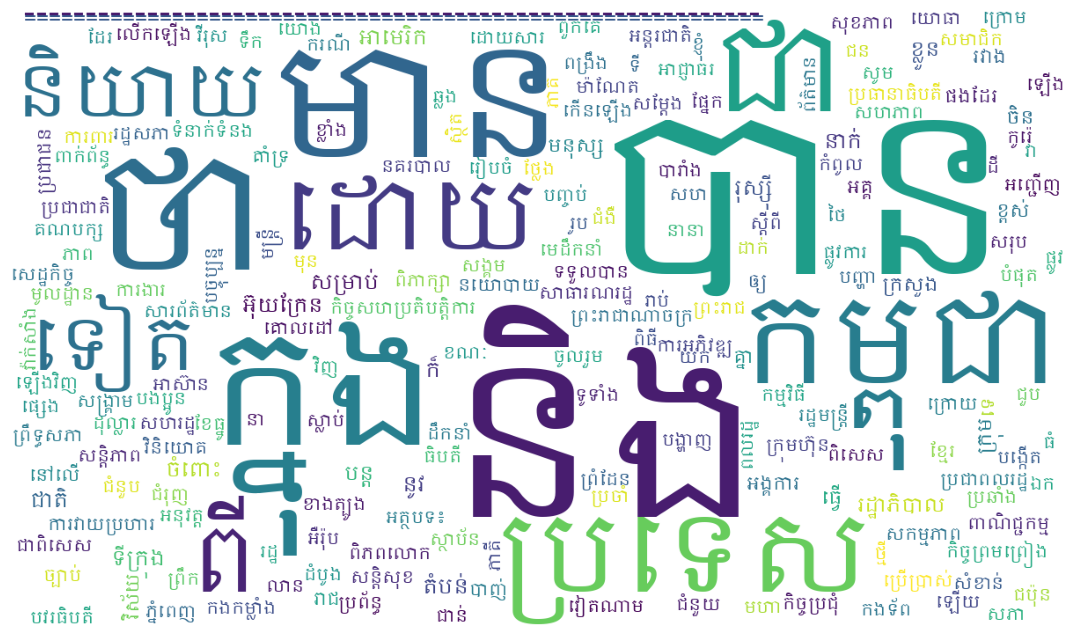

In [33]:
# FULL runnable cell: build all_words from df["tokens"] and visualize Khmer word cloud

from collections import Counter
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# 1) Recreate all_words safely
all_words = [word for tokens in df["tokens"] for word in tokens]

# 2) Build frequency dictionary
word_freq = Counter(all_words)

# 3) Optional: remove very short/noise tokens
word_freq = {w: c for w, c in word_freq.items() if len(w) > 1}

# 4) IMPORTANT: Khmer-supporting font (change if needed)
khmer_font_path = r"C:\Windows\Fonts\KhmerOS.ttf"

# 5) Generate word cloud
wc = WordCloud(
    font_path=khmer_font_path,
    width=1200,
    height=700,
    background_color="white",
    collocations=False
).generate_from_frequencies(word_freq)

# 6) Display
plt.figure(figsize=(14, 8))
plt.imshow(wc)
plt.axis("off")
plt.show()


In [34]:
from collections import Counter

word_freq = Counter(all_words)

# optional: remove very short noise
word_freq = {w: c for w, c in word_freq.items() if len(w) > 1}

# Top 20 most frequent words
top20_words = [word for word, _ in Counter(word_freq).most_common(15)]

print("Top 20 words to remove:")
print(top20_words)


Top 20 words to remove:
['បាន', 'និង', 'ថា', 'មាន', 'ក្នុង', 'កម្ពុជា', 'ជា', 'ប្រទេស', 'ដោយ', 'ពី', 'និយាយ', 'ទៀត', '------------------------------------------------------------', '============================================================', 'ក៏']


In [35]:
filtered_word_freq = {
    w: c for w, c in word_freq.items()
    if w not in top20_words
}


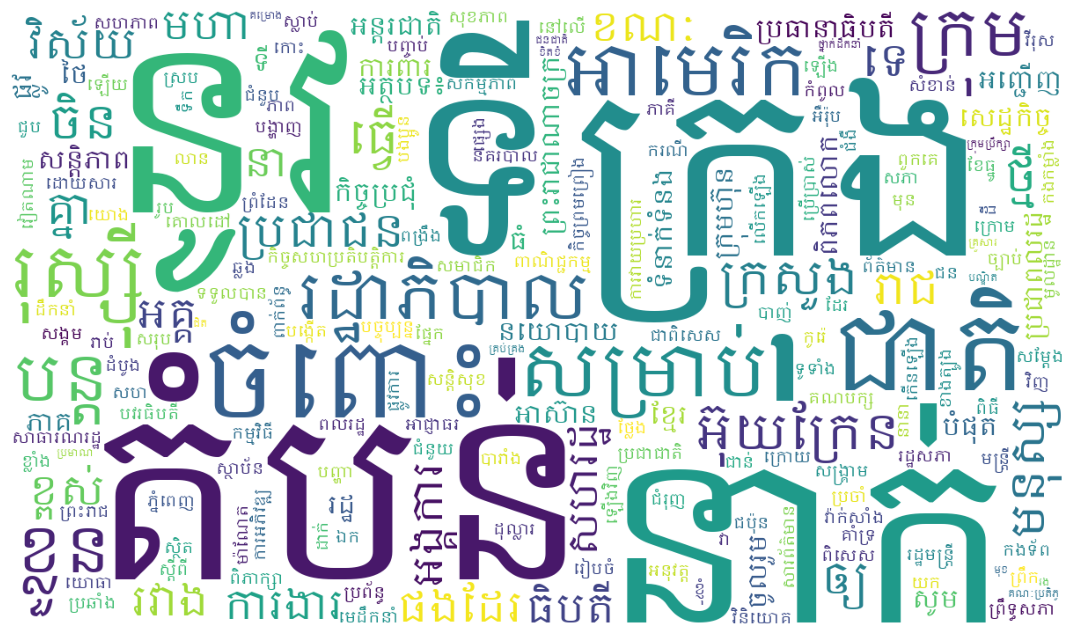

In [36]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

font_path = r"C:\Windows\Fonts\KhmerOS.ttf"  # change if needed

wc = WordCloud(
    font_path=font_path,
    width=1200,
    height=700,
    background_color="white",
    collocations=False
).generate_from_frequencies(filtered_word_freq)

plt.figure(figsize=(14, 8))
plt.imshow(wc)
plt.axis("off")
plt.show()


In [37]:
filtered_all_words = [
    w for w in all_words if w not in top20_words
]


In [38]:
unique_words = sorted(set(filtered_all_words))

print(f"Total unique words (after removing top 20): {len(unique_words)}")


Total unique words (after removing top 20): 28142


In [39]:
df_words = pd.DataFrame(unique_words, columns=["word"])
df_words.head()

,word
0,
1,!
2,!!
3,!!!
4,!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!...


In [40]:
df_words = df_words[df_words["word"].str.len() > 1].reset_index(drop=True)


In [41]:
# Remove top-20 frequent words from each document
df["tokens_clean"] = df["tokens"].apply(
    lambda tokens: [w for w in tokens if w not in top20_words and len(w) > 1]
)


In [42]:
df["text_tfidf"] = df["tokens_clean"].apply(lambda x: " ".join(x))


In [43]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    token_pattern=r"[^ ]+",   # keep Khmer tokens intact
    lowercase=False,          # Khmer has no case
    min_df=2                  # optional: remove very rare words
)

X_tfidf = tfidf.fit_transform(df["text_tfidf"])


In [44]:
print("TF-IDF matrix shape:", X_tfidf.shape)


TF-IDF matrix shape: (88307, 14922)


In [45]:
import re

# Noise pattern (punctuation, repeated symbols, etc.)
noise_pattern = r"[!\"#$%&'()*+,./:;<=>?@[\]^_`{|}~\u200b\u200c\u200d…«»“”៕៖]"

def clean_feature(name):
    # Remove noise
    cleaned = re.sub(noise_pattern, "", name)
    # Remove empty strings
    return cleaned.strip()


In [46]:
# Get original feature names
feature_names = tfidf.get_feature_names_out()

# Clean feature names
feature_names_clean = [clean_feature(f) for f in feature_names]

# Optionally remove empty features after cleaning
non_empty_idx = [i for i, f in enumerate(feature_names_clean) if f]

# Apply mask to TF-IDF matrix
X_tfidf_clean = X_tfidf[:, non_empty_idx]

# Create DataFrame
tfidf_df = pd.DataFrame(
    X_tfidf_clean.toarray(),
    columns=[feature_names_clean[i] for i in non_empty_idx]
)

tfidf_df.head()


,ន,ស,នា,របួស,-,-,-,–,-,ទទឹង,...,។ចំណែក,។ជា,។ធិបតី,។បន្ទាប់ពី,។ល,។ល។,។សង្ឃឹម,ៗ,ក,‎‎
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [47]:
# def top_keywords(row, n=10):
#     return row.sort_values(ascending=False).head(n)

# top_words_per_doc = tfidf_df.apply(top_keywords, axis=1)

# top_words_per_doc.head()


In [48]:
import re

# Khmer Unicode blocks
KHMER_SUBSCRIPT = r"[\u17D2]"                 # ◌្
KHMER_DIACRITICS = r"[\u17B6-\u17D1\u17DD]"   # vowels & signs
KHMER_PUNCT = r"[។៖ៗ៕៚]"                      # punctuation


In [49]:
def is_invalid_khmer_token(token: str) -> bool:
    # only subscript or diacritics
    if re.fullmatch(rf"{KHMER_SUBSCRIPT}+[\u1780-\u17A2]?", token):
        return True

    # only diacritics
    if re.fullmatch(rf"{KHMER_DIACRITICS}+", token):
        return True

    # punctuation
    if re.fullmatch(KHMER_PUNCT, token):
        return True

    # very short garbage (single char but not independent vowel)
    if len(token) == 1 and not re.match(r"[\u17A3-\u17B3]", token):
        return True

    return False


In [50]:
df["tokens_clean"] = df["tokens"].apply(
    lambda tokens: [
        w for w in tokens
        if not is_invalid_khmer_token(w)
    ]
)


In [51]:
all_words = [w for tokens in df["tokens_clean"] for w in tokens]


In [52]:
unique_words = sorted(set(all_words))
print(f"Total unique words (clean): {len(unique_words)}")


Total unique words (clean): 28003


In [53]:
# Show some cleaned tokens
for i in range(3):
    print(df["tokens_clean"].iloc[i][:30])


['សាលា', 'ទទួលបាន', 'លិខិត', 'សុំ', 'ធ្វើ', 'បាតុកម្ម', 'ក្រុម', 'សម្ព័ន្ធ', 'យុវជន', 'គាំទ្រ', 'គណបក្ស', 'ប្រជាជន', 'នៅឡើយ', 'ភ្នំពេញ', 'សាលា', 'ទទួលបាន', 'លិខិត', 'ជា', 'ផ្លូវការ', 'ធ្វើ', 'បាតុកម្ម', 'ពី', 'ក្រុម', 'សម្ព័ន្ធ', 'យុវជន', 'គាំទ្រ', 'គណបក្ស', 'ប្រជាជន', 'កម្ពុជា', 'ប្រឆាំង']
['យប់', 'ប៉ូលិស', 'ដាក់', 'ប៉ុស្តិ៍', 'បងប្អូន', 'ស្រវឹង', 'ស្រា', 'សូម', 'កុំ', 'បើកបរ', 'ជៀសវាង', 'ការពិន័យ', 'ធ្ងន់ធ្ងរ', 'និង', 'គ្រោះថ្នាក់', 'ភ្នំពេញ', 'រុន', 'រ័ត្ន', 'វាសនា', 'នាយកដ្ឋាន', 'នគរបាល', 'ចរាចរណ៍', 'និង', 'សណ្តាប់ធ្នាប់', 'សាធារណៈ', 'បាន', 'អង្គភាព', 'ព័ត៌មាន', 'ទទួលបាន', 'ព្រលប់']
['ឃួន', 'សុដារី', 'អនុប្រធាន', 'កាកបាទ', 'ក្រហម', 'កម្ពុជា', 'បំពាក់', 'គ្រឿង', 'ឥស្សរិយយស', 'អាន', 'អេលី', 'សាប៊េត', 'ឡឺឃ្លែ', 'ភ្នំពេញ', 'ឃួន', 'សុដារី', 'អនុប្រធាន', 'កាកបាទ', 'ក្រហម', 'កម្ពុជា', 'តំណាង', 'ឲ្យ', 'កិត្តិព្រឹទ្ធបណ្ឌិត', 'បាន', 'ជួប', 'សម្ដែង', 'ការគួរសម', 'និង', 'បំពាក់', 'គ្រឿង']


In [54]:
bad_like = [w for w in set(all_words) if len(w) <= 2]
print(bad_like[:30])


['ផន', 'ហា', 'ខោ', 'ដូ', 'σε', 'តា', 'ម.', '។.', 'បោ', 'ដន', 'ខឺ', ')»', 'យី', 'ឪ', 'មិ', 'ជៃ', 'ឌូ', 'ករ', 'ទា', 'ថម', 'ឫក', 'រង', 'ឆា', 'កី', 'ហែ', 'លប', 'ឩ', 'ធិ', 'ឡន', 'យ់']


In [55]:
df["tfidf_text"] = df["tokens_clean"].apply(lambda x: " ".join(x))


In [56]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    token_pattern=r"[^ ]+",   # KEEP Khmer tokens intact
    lowercase=False,          # Khmer has no case
    min_df=2                  # optional: remove very rare noise
)

X_tfidf = tfidf.fit_transform(df["tfidf_text"])


In [57]:
print("TF-IDF shape:", X_tfidf.shape)


TF-IDF shape: (88307, 14946)


In [65]:
features = tfidf.get_feature_names_out()
print(features[:100])


['!!' '!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!' '!"'
 '!|' '!»' '""' '")' '"ន' '$ស.' "''" '()' '()នា' '()របួស' '(-' '(-)'
 '(-)»' '(–)' '),' ')-' '):' ')»' ')ទទឹង' ')នា' ')បាន' ')ស្មើ' ')៕' ')៖'
 ')”' '**' '**ប្រសាសន៍' '-)' '--'
 '----------------------------------------'
 '------------------------------------------------------------' '-»' '-”'
 '..' '...' '....' '.ក' '.ច' '.ប' '.ប.' '.ម' '.យ' '.ស' '.ស.' '.ស.ប' '.ស.ស'
 '.ស.ស.' '.៖' '/ណ្ឌ' ':«' '==' '===' '===='
 '============================================================'
 '================================================================================'
 '[]' '[].' '[]..' '[…]' '])'
 '_____________________________________________' '««' '«»' '»!' '»(-)'
 '»,' '»ក្នុង' '»នា' '»ហើយ' '»។' '»៕' 'ក)' 'ក.' 'កក' 'កកកុញ' 'កកស្ទះ'
 'កកាយ' 'កកុញ' 'កកើត' 'កកើតឡើង' 'កក់' 'កក់ក្ដៅ' 'កក់ក្តៅ' 'កក់ខែ' 'កក្កដា'
 'កក្ដ' 'កក្រើក' 'កខ្វក់' 'កង' 'កងកម្លាំង' 'កងកម្លាំងប្រដាប់'
 'កងកម្លាំងប្រដាប់អាវុធ' 'កងទ័ព' 'កងពល' 'កងយោធពល' 'កងរាជអ

In [66]:
import re

# Keep only Khmer letters and numbers
khmer_pattern = r"[^\u1780-\u17FF\u17E0-\u17E9]+"  

def clean_feature(feature, min_len=3):
    # Remove non-Khmer characters
    f = re.sub(khmer_pattern, "", feature).strip()
    
    # Remove very short tokens
    if len(f) < min_len:
        return None
    return f

# Apply cleaning
features_cleaned = [clean_feature(f) for f in features]

# Remove None / empty features
features_cleaned = [f for f in features_cleaned if f]

print(features_cleaned[:100])


['របួស', 'ទទឹង', 'បាន', 'ស្មើ', 'ប្រសាសន៍', 'ណ្ឌ', 'ក្នុង', 'ហើយ', 'កកកុញ', 'កកស្ទះ', 'កកាយ', 'កកុញ', 'កកើត', 'កកើតឡើង', 'កក់', 'កក់ក្ដៅ', 'កក់ក្តៅ', 'កក់ខែ', 'កក្កដា', 'កក្ដ', 'កក្រើក', 'កខ្វក់', 'កងកម្លាំង', 'កងកម្លាំងប្រដាប់', 'កងកម្លាំងប្រដាប់អាវុធ', 'កងទ័ព', 'កងពល', 'កងយោធពល', 'កងរាជអាវុធហត្ថ', 'កង់', 'កង្កែប', 'កង្វក់', 'កង្វល់', 'កង្វះ', 'កង្វះខាត', 'កង្ហារ', 'កញ្ចក់', 'កញ្ចប់', 'កញ្ជ្រឹល', 'កញ្រ្ជឹល', 'កដ្ឋ', 'កឋិន', 'កណ្ដា', 'កណ្ដាប់ដៃ', 'កណ្ដាល', 'កណ្ដឹង', 'កណ្ឋាភរណ', 'កណ្តាប់ដៃ', 'កណ្តាល', 'កណ្តាល៖', 'កណ្តាស', 'កណ្តឹង', 'កណ្តុរ', 'កតញ្ញូ', 'កតញ្ញូកតវេទិតាធម៌', 'កតញ្ញូតាធម៌', 'កតព្វកិច្ច', 'កតិកាសញ្ញា', 'កត់', 'កត់ត្រា', 'កត់សម្កាល់', 'កត់សម្គាល់', 'កត់សំគាល់', 'កត្ដា', 'កត្ត', 'កត្តា', 'កត្តិ', 'កថា', 'កនាំ', 'កន្តើយ', 'កន្ត្រក', 'កន្ត្រាក់', 'កន្ត្រៃ', 'កន្ត្រៃយ៍', 'កន្ថា', 'កន្ថោរ', 'កន្ទុយ', 'កន្ទេល', 'កន្ទោក', 'កន្ល', 'កន្លង', 'កន្លងទៅ', 'កន្លងទៅជា', 'កន្លងផុត', 'កន្លងមក', 'កន្លងមកដល់', 'កន្លងហួស', 'កន្លែ', 'កន្លែង', 'កន្លែងទុកដាក់', 'កន្លះ', 'កន្សែង', 'កប៉ាល់', 'កប់', '

In [74]:
# 1️⃣ Define Khmer punctuation to remove
khmer_punct = {"ៗ", "៖", "។", "៕", "…" }

# 2️⃣ Remove these punctuation from tokenized lists
df["tokens_clean"] = df["tokens_clean"].apply(
    lambda tokens: [w for w in tokens if w not in khmer_punct]
)

# 3️⃣ Optional: Check first 3 documents (first 30 tokens)
for i in range(3):
    print(f"\nDocument {i+1} tokens (first 30):")
    print(df["tokens_clean"].iloc[i][:30])



Document 1 tokens (first 30):
['សាលា', 'ទទួលបាន', 'លិខិត', 'សុំ', 'ធ្វើ', 'បាតុកម្ម', 'ក្រុម', 'សម្ព័ន្ធ', 'យុវជន', 'គាំទ្រ', 'គណបក្ស', 'ប្រជាជន', 'នៅឡើយ', 'ភ្នំពេញ', 'សាលា', 'ទទួលបាន', 'លិខិត', 'ជា', 'ផ្លូវការ', 'ធ្វើ', 'បាតុកម្ម', 'ពី', 'ក្រុម', 'សម្ព័ន្ធ', 'យុវជន', 'គាំទ្រ', 'គណបក្ស', 'ប្រជាជន', 'កម្ពុជា', 'ប្រឆាំង']

Document 2 tokens (first 30):
['យប់', 'ប៉ូលិស', 'ដាក់', 'ប៉ុស្តិ៍', 'បងប្អូន', 'ស្រវឹង', 'ស្រា', 'សូម', 'កុំ', 'បើកបរ', 'ជៀសវាង', 'ការពិន័យ', 'ធ្ងន់ធ្ងរ', 'និង', 'គ្រោះថ្នាក់', 'ភ្នំពេញ', 'រុន', 'រ័ត្ន', 'វាសនា', 'នាយកដ្ឋាន', 'នគរបាល', 'ចរាចរណ៍', 'និង', 'សណ្តាប់ធ្នាប់', 'សាធារណៈ', 'បាន', 'អង្គភាព', 'ព័ត៌មាន', 'ទទួលបាន', 'ព្រលប់']

Document 3 tokens (first 30):
['ឃួន', 'សុដារី', 'អនុប្រធាន', 'កាកបាទ', 'ក្រហម', 'កម្ពុជា', 'បំពាក់', 'គ្រឿង', 'ឥស្សរិយយស', 'អាន', 'អេលី', 'សាប៊េត', 'ឡឺឃ្លែ', 'ភ្នំពេញ', 'ឃួន', 'សុដារី', 'អនុប្រធាន', 'កាកបាទ', 'ក្រហម', 'កម្ពុជា', 'តំណាង', 'ឲ្យ', 'កិត្តិព្រឹទ្ធបណ្ឌិត', 'បាន', 'ជួប', 'សម្ដែង', 'ការគួរសម', 'និង', 'បំពាក់', 'គ្រឿង']


In [75]:
# Check first 3 documents
for i in range(3):
    print(df["tokens_clean"].iloc[i][:30])


['សាលា', 'ទទួលបាន', 'លិខិត', 'សុំ', 'ធ្វើ', 'បាតុកម្ម', 'ក្រុម', 'សម្ព័ន្ធ', 'យុវជន', 'គាំទ្រ', 'គណបក្ស', 'ប្រជាជន', 'នៅឡើយ', 'ភ្នំពេញ', 'សាលា', 'ទទួលបាន', 'លិខិត', 'ជា', 'ផ្លូវការ', 'ធ្វើ', 'បាតុកម្ម', 'ពី', 'ក្រុម', 'សម្ព័ន្ធ', 'យុវជន', 'គាំទ្រ', 'គណបក្ស', 'ប្រជាជន', 'កម្ពុជា', 'ប្រឆាំង']
['យប់', 'ប៉ូលិស', 'ដាក់', 'ប៉ុស្តិ៍', 'បងប្អូន', 'ស្រវឹង', 'ស្រា', 'សូម', 'កុំ', 'បើកបរ', 'ជៀសវាង', 'ការពិន័យ', 'ធ្ងន់ធ្ងរ', 'និង', 'គ្រោះថ្នាក់', 'ភ្នំពេញ', 'រុន', 'រ័ត្ន', 'វាសនា', 'នាយកដ្ឋាន', 'នគរបាល', 'ចរាចរណ៍', 'និង', 'សណ្តាប់ធ្នាប់', 'សាធារណៈ', 'បាន', 'អង្គភាព', 'ព័ត៌មាន', 'ទទួលបាន', 'ព្រលប់']
['ឃួន', 'សុដារី', 'អនុប្រធាន', 'កាកបាទ', 'ក្រហម', 'កម្ពុជា', 'បំពាក់', 'គ្រឿង', 'ឥស្សរិយយស', 'អាន', 'អេលី', 'សាប៊េត', 'ឡឺឃ្លែ', 'ភ្នំពេញ', 'ឃួន', 'សុដារី', 'អនុប្រធាន', 'កាកបាទ', 'ក្រហម', 'កម្ពុជា', 'តំណាង', 'ឲ្យ', 'កិត្តិព្រឹទ្ធបណ្ឌិត', 'បាន', 'ជួប', 'សម្ដែង', 'ការគួរសម', 'និង', 'បំពាក់', 'គ្រឿង']


In [76]:
df["tfidf_text"] = df["tokens_clean"].apply(lambda x: " ".join(x))


In [77]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    token_pattern=r"[^ ]+",   # keep Khmer tokens intact
    lowercase=False,
    min_df=2
)

X_tfidf = tfidf.fit_transform(df["tfidf_text"])


In [78]:
features = tfidf.get_feature_names_out()
print(features[:30])


['!!' '!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!' '!"'
 '!|' '!»' '""' '")' '"ន' '$ស.' "''" '()' '()នា' '()របួស' '(-' '(-)'
 '(-)»' '(–)' '),' ')-' '):' ')»' ')ទទឹង' ')នា' ')បាន' ')ស្មើ' ')៕' ')៖'
 ')”' '**' '**ប្រសាសន៍']


In [ ]:
X_tfidf = tfidf.fit_transform(df["tfidf_text"])
features = tfidf.get_feature_names_out()


In [80]:
font_path = r"C:\Windows\Fonts\KhmerOS.ttf"  # adjust if needed


In [82]:
from collections import Counter

# Flatten all token lists into a single list
all_tokens = [token for tokens in df["tokens_clean"] for token in tokens]

# Count token frequencies
word_scores = dict(Counter(all_tokens))

# Optional: remove very short tokens (single-character noise)
word_scores = {w: c for w, c in word_scores.items() if len(w) > 2}

# Check top 10
print(sorted(word_scores.items(), key=lambda x: x[1], reverse=True)[:10])


[('បាន', 61778), ('និង', 57585), ('មាន', 26541), ('ក្នុង', 26524), ('កម្ពុជា', 21946), ('ប្រទេស', 18706), ('ដោយ', 14403), ('និយាយ', 7721), ('ទៀត', 7633), ('------------------------------------------------------------', 7242)]


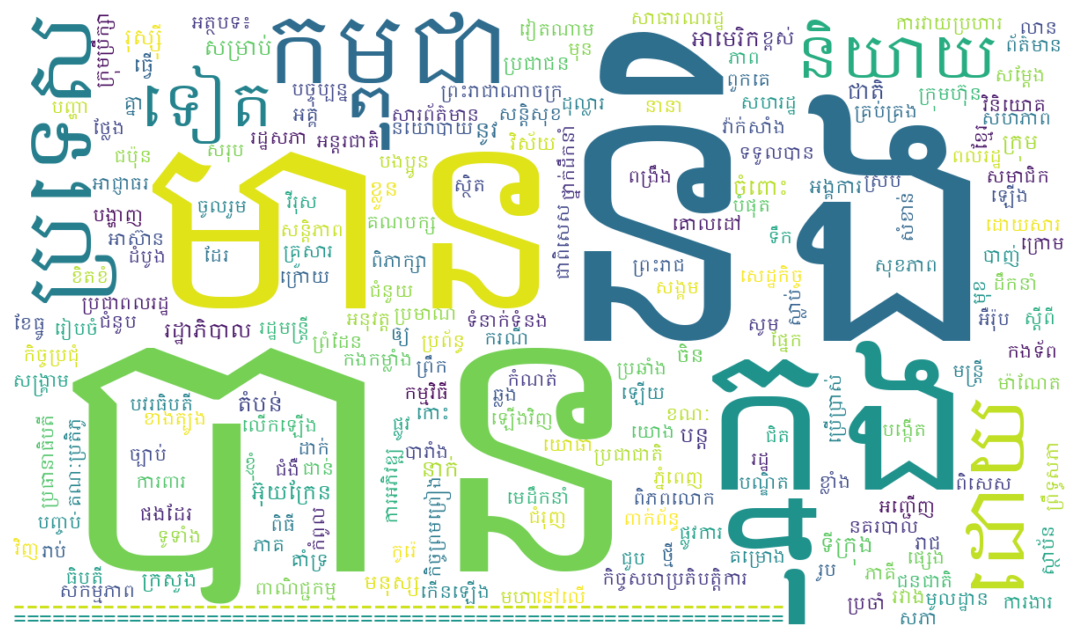

In [83]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

wc = WordCloud(
    font_path=font_path,
    width=1200,
    height=700,
    background_color="white",
    collocations=False
).generate_from_frequencies(word_scores)

plt.figure(figsize=(14, 8))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.show()


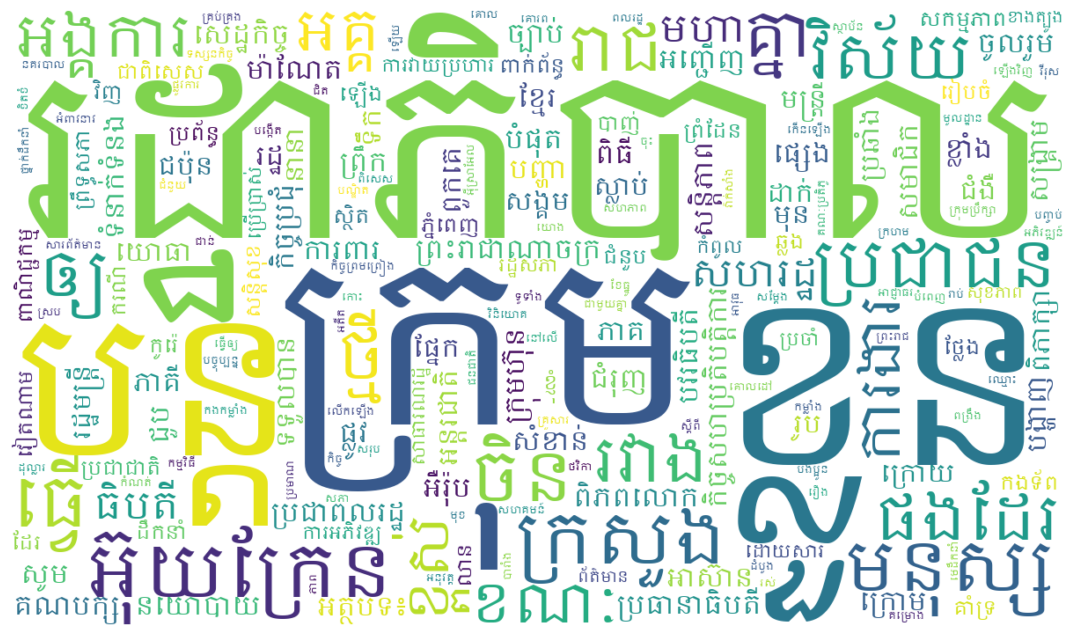

In [84]:
# Remove top 20 by weight
top20 = sorted(word_scores, key=word_scores.get, reverse=True)[:20]
word_scores_filtered = {w: s for w, s in word_scores.items() if w not in top20}

# Regenerate WordCloud
wc = WordCloud(font_path=font_path, width=1200, height=700,
               background_color="white", collocations=False)\
               .generate_from_frequencies(word_scores_filtered)
plt.figure(figsize=(14, 8))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.show()


In [85]:
import pandas as pd

# Create DataFrame: rows = documents, columns = words
tfidf_df = pd.DataFrame(
    X_tfidf.toarray(),
    columns=features
)

# Optional: add document identifier
tfidf_df.insert(0, "document_id", df.index)


In [94]:
import pandas as pd
import re

# Flatten all cleaned tokens
all_words = [w for tokens in df["tokens_clean"] for w in tokens]

# Remove duplicates
unique_words = set(all_words)

# Filter to keep only valid Khmer words
# Khmer characters: \u1780-\u17B3 (consonants, vowels, etc.)
# Exclude Khmer punctuation: \u17D4-\u17DC (។ ៕ ៖ ៗ etc.)
# Exclude Khmer signs/symbols that shouldn't start words
khmer_only_words = []
for word in unique_words:
    # Must contain only Khmer script (no Latin, numbers, other scripts)
    if re.match(r'^[\u1780-\u17FF]+$', word):
        # Must NOT start with Khmer punctuation marks
        if not re.match(r'^[\u17D4-\u17DC]', word):
            # Must NOT start with Khmer vowel signs (dependent vowels shouldn't be first)
            if not re.match(r'^[\u17B6-\u17C5]', word):
                khmer_only_words.append(word)

# Sort the filtered words
khmer_only_words = sorted(khmer_only_words)

# Create DataFrame
df_words = pd.DataFrame(khmer_only_words, columns=["word"])

# Add character-level tokenization
df_words["char_tokens"] = df_words["word"].apply(lambda w: " ".join(list(w)))

# Save to CSV
df_words.to_csv("khmer_unique_words.csv", index=False, encoding="utf-8-sig")

print(f"Total unique words before filtering: {len(unique_words)}")
print(f"Khmer-only words after filtering: {len(khmer_only_words)}")
print(f"\nSaved to: khmer_unique_words.csv")
print(f"\nFirst few examples:")
print(df_words.head(10))

Total unique words before filtering: 28003
Khmer-only words after filtering: 27459

Saved to: khmer_unique_words.csv

First few examples:
        word        char_tokens
0         កក                ក ក
1      កកកុញ          ក ក ក ុ ញ
2    កកក្កដា      ក ក ក ្ ក ដ ា
3  កកម្សាន្ត  ក ក ម ្ ស ា ន ្ ត
4     កកស្ទះ        ក ក ស ្ ទ ះ
5       កកាយ            ក ក ា យ
6  កការកងទ័ព  ក ក ា រ ក ង ទ ័ ព
7       កកុញ            ក ក ុ ញ
8       កកើត            ក ក ើ ត
9    កកើតឡើង      ក ក ើ ត ឡ ើ ង


# Pretrain

In [122]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import unicodedata
from collections import Counter

# ============================================================================
# 1. PREPROCESSING & VOCABULARY
# ============================================================================

def preprocess_word(word):
    """Apply NFC normalization and clean"""
    return unicodedata.normalize('NFC', word.strip())

def build_vocab(words, min_freq=1):
    """Build character vocabulary from words"""
    char_counter = Counter()
    for word in words:
        word = preprocess_word(word)
        char_counter.update(list(word))
    
    # Special tokens
    special_tokens = ['<PAD>', '<SOS>', '<EOS>', '<UNK>']
    
    # Filter by frequency and build vocab
    vocab = special_tokens + [char for char, freq in char_counter.items() if freq >= min_freq]
    
    char2id = {char: idx for idx, char in enumerate(vocab)}
    id2char = {idx: char for char, idx in char2id.items()}
    
    return vocab, char2id, id2char

# ============================================================================
# 2. DATASET
# ============================================================================

class KhmerWordDataset(Dataset):
    def __init__(self, words, char2id, max_len=40):
        self.words = [preprocess_word(w) for w in words]
        self.char2id = char2id
        self.max_len = max_len
        self.pad_id = char2id['<PAD>']
        self.sos_id = char2id['<SOS>']
        self.eos_id = char2id['<EOS>']
        self.unk_id = char2id['<UNK>']
    
    def __len__(self):
        return len(self.words)
    
    def encode_word(self, word):
        """Encode word to character IDs"""
        return [self.char2id.get(c, self.unk_id) for c in word]
    
    def __getitem__(self, idx):
        word = self.words[idx]
        char_ids = self.encode_word(word)
        
        # Encoder input: [char_ids] + [<EOS>] + padding
        enc_in = char_ids + [self.eos_id]
        enc_in = enc_in[:self.max_len]  # Truncate if too long
        enc_in = enc_in + [self.pad_id] * (self.max_len - len(enc_in))  # Pad
        
        # Decoder input: [<SOS>] + [char_ids] + padding
        dec_in = [self.sos_id] + char_ids
        dec_in = dec_in[:self.max_len]
        dec_in = dec_in + [self.pad_id] * (self.max_len - len(dec_in))
        
        # Decoder target: [char_ids] + [<EOS>] + padding
        dec_tgt = char_ids + [self.eos_id]
        dec_tgt = dec_tgt[:self.max_len]
        dec_tgt = dec_tgt + [self.pad_id] * (self.max_len - len(dec_tgt))
        
        return {
            'enc_in': torch.tensor(enc_in, dtype=torch.long),
            'dec_in': torch.tensor(dec_in, dtype=torch.long),
            'dec_tgt': torch.tensor(dec_tgt, dtype=torch.long),
            'word': word
        }

# ============================================================================
# 3. MODEL ARCHITECTURE
# ============================================================================

class KhmerAutoencoder(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=512, num_layers=1):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        
        # Shared embedding layer
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        # Encoder: BiGRU
        self.encoder = nn.GRU(
            embed_dim, 
            hidden_dim // 2,  # Divide by 2 because bidirectional
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True
        )
        
        # Decoder: Unidirectional GRU
        self.decoder = nn.GRU(
            embed_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )
        
        # Output projection
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
    
    def forward(self, enc_in, dec_in):
        """
        enc_in: (batch, max_len) - encoder input IDs
        dec_in: (batch, max_len) - decoder input IDs
        """
        # (1) Embedding
        enc_emb = self.embedding(enc_in)  # (batch, max_len, embed_dim)
        dec_emb = self.embedding(dec_in)  # (batch, max_len, embed_dim)
        
        # (2) Encoder
        enc_out, enc_hidden = self.encoder(enc_emb)
        # enc_out: (batch, max_len, hidden_dim)
        # enc_hidden: (num_layers*2, batch, hidden_dim//2) for bidirectional
        
        # (3) Latent vector z: use final hidden state
        # Concatenate forward and backward final states
        if self.encoder.bidirectional:
            # enc_hidden shape: (num_layers*2, batch, hidden_dim//2)
            # Get last layer's forward and backward
            z = torch.cat([enc_hidden[-2], enc_hidden[-1]], dim=1)  # (batch, hidden_dim)
        else:
            z = enc_hidden[-1]  # (batch, hidden_dim)
        
        # (4) Initialize decoder hidden state
        h0 = z.unsqueeze(0)  # (1, batch, hidden_dim)
        
        # (5) Decoder
        dec_out, _ = self.decoder(dec_emb, h0)
        # dec_out: (batch, max_len, hidden_dim)
        
        # (6) Project to vocabulary
        logits = self.fc_out(dec_out)  # (batch, max_len, vocab_size)
        
        return logits, z

# ============================================================================
# 4. TRAINING
# ============================================================================

def train_autoencoder(model, dataloader, optimizer, criterion, device, num_epochs=10):
    model.train()
    
    for epoch in range(num_epochs):
        total_loss = 0
        for batch in dataloader:
            enc_in = batch['enc_in'].to(device)
            dec_in = batch['dec_in'].to(device)
            dec_tgt = batch['dec_tgt'].to(device)
            
            # Forward pass
            logits, z = model(enc_in, dec_in)
            
            # Reshape for loss calculation
            # logits: (batch, max_len, vocab_size) -> (batch*max_len, vocab_size)
            # dec_tgt: (batch, max_len) -> (batch*max_len)
            logits_flat = logits.view(-1, logits.size(-1))
            dec_tgt_flat = dec_tgt.view(-1)
            
            # Calculate loss (ignoring padding)
            loss = criterion(logits_flat, dec_tgt_flat)
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
        
        avg_loss = total_loss / len(dataloader)
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {avg_loss:.4f}")

# ============================================================================
# 5. MAIN EXECUTION
# ============================================================================

if __name__ == "__main__":
    # Load data
    print("Loading data...")
    df_words = pd.read_csv("khmer_unique_words.csv")
    words = df_words['word'].tolist()
    
    print(f"Total words: {len(words)}")
    print(f"Sample words: {words[:5]}")
    
    # Build vocabulary
    print("\nBuilding vocabulary...")
    vocab, char2id, id2char = build_vocab(words, min_freq=1)
    print(f"Vocabulary size: {len(vocab)}")
    print(f"Special tokens: {vocab[:4]}")
    print(f"Sample characters: {vocab[4:14]}")
    
    # Create dataset
    print("\nCreating dataset...")
    max_len = 40
    dataset = KhmerWordDataset(words, char2id, max_len=max_len)
    dataloader = DataLoader(dataset, batch_size=64, shuffle=True)
    
    # Initialize model
    print("\nInitializing model...")
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")
    
    model = KhmerAutoencoder(
        vocab_size=len(vocab),
        embed_dim=64,
        hidden_dim=512,
        num_layers=1
    ).to(device)
    
    # Loss and optimizer (ignore padding in loss)
    criterion = nn.CrossEntropyLoss(ignore_index=char2id['<PAD>'])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    
    print(f"\nModel parameters: {sum(p.numel() for p in model.parameters()):,}")
    
    # Train
    print("\nTraining...")
    train_autoencoder(model, dataloader, optimizer, criterion, device, num_epochs=20)
    
    # Save model and vocab
    print("\nSaving model...")
    torch.save({
        'model_state_dict': model.state_dict(),
        'vocab': vocab,
        'char2id': char2id,
        'id2char': id2char,
        'max_len': max_len
    }, 'khmer_autoencoder.pt')
    
    print("Training complete!")

Loading data...
Total words: 27459
Sample words: ['កក', 'កកកុញ', 'កកក្កដា', 'កកម្សាន្ត', 'កកស្ទះ']

Building vocabulary...
Vocabulary size: 87
Special tokens: ['<PAD>', '<SOS>', '<EOS>', '<UNK>']
Sample characters: ['ក', 'ុ', 'ញ', '្', 'ដ', 'ា', 'ម', 'ស', 'ន', 'ត']

Creating dataset...

Initializing model...
Using device: cuda

Model parameters: 1,432,599

Training...
Epoch 1/20, Loss: 1.2017
Epoch 2/20, Loss: 0.2228
Epoch 3/20, Loss: 0.1023
Epoch 4/20, Loss: 0.0602
Epoch 5/20, Loss: 0.0438
Epoch 6/20, Loss: 0.0457
Epoch 7/20, Loss: 0.0309
Epoch 8/20, Loss: 0.0299
Epoch 9/20, Loss: 0.0235
Epoch 10/20, Loss: 0.0250
Epoch 11/20, Loss: 0.0201
Epoch 12/20, Loss: 0.0207
Epoch 13/20, Loss: 0.0227
Epoch 14/20, Loss: 0.0211
Epoch 15/20, Loss: 0.0170
Epoch 16/20, Loss: 0.0170
Epoch 17/20, Loss: 0.0197
Epoch 18/20, Loss: 0.0163
Epoch 19/20, Loss: 0.0154
Epoch 20/20, Loss: 0.0153

Saving model...
Training complete!


In [124]:
import torch
import pandas as pd

# Load model
checkpoint = torch.load('khmer_autoencoder.pt')
model.load_state_dict(checkpoint['model_state_dict'])
char2id = checkpoint['char2id']
id2char = checkpoint['id2char']
max_len = checkpoint['max_len']

def reconstruct_word(model, word, char2id, id2char, max_len, device):
    """Reconstruct a word through the autoencoder"""
    model.eval()
    
    # Prepare input
    dataset = KhmerWordDataset([word], char2id, max_len)
    batch = dataset[0]
    
    enc_in = batch['enc_in'].unsqueeze(0).to(device)
    dec_in = batch['dec_in'].unsqueeze(0).to(device)
    
    with torch.no_grad():
        logits, z = model(enc_in, dec_in)
        predictions = logits.argmax(dim=-1)  # (1, max_len)
    
    # Decode predictions
    pred_ids = predictions[0].cpu().numpy()
    reconstructed = []
    for id in pred_ids:
        char = id2char[id]
        if char == '<EOS>':
            break
        if char not in ['<PAD>', '<SOS>']:
            reconstructed.append(char)
    
    return ''.join(reconstructed), z

# Test
test_words = ["ដេក", "ភ្នំពេញ", "កម្ពុជា"]
for word in test_words:
    recon, latent = reconstruct_word(model, word, char2id, id2char, max_len, device)
    print(f"Original: {word} → Reconstructed: {recon}")

Original: ដេក → Reconstructed: ដេក
Original: ភ្នំពេញ → Reconstructed: ភ្នំពេញ
Original: កម្ពុជា → Reconstructed: កម្ពុជា


C:\Users\ROG STRIX\AppData\Local\Temp\ipykernel_18700\1368817729.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load('khmer_autoencoder.pt')


In [125]:
def extract_all_embeddings(model, words, char2id, max_len, device):
    """Extract latent vectors for all words"""
    model.eval()
    
    embeddings = []
    word_list = []
    
    dataset = KhmerWordDataset(words, char2id, max_len)
    dataloader = DataLoader(dataset, batch_size=128, shuffle=False)
    
    with torch.no_grad():
        for batch in dataloader:
            enc_in = batch['enc_in'].to(device)
            dec_in = batch['dec_in'].to(device)
            
            _, z = model(enc_in, dec_in)
            embeddings.append(z.cpu().numpy())
            word_list.extend(batch['word'])
    
    embeddings = np.vstack(embeddings)
    return embeddings, word_list

# Extract embeddings
embeddings, word_list = extract_all_embeddings(model, words, char2id, max_len, device)

# Save embeddings
df_embeddings = pd.DataFrame(embeddings)
df_embeddings['word'] = word_list
df_embeddings.to_csv('khmer_word_embeddings.csv', index=False, encoding='utf-8-sig')

# fINE TUNE 


In [126]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import unicodedata

# ============================================================================
# 0. STAGE 1 MODEL ARCHITECTURE (Copy from Stage 1)
# ============================================================================

class KhmerAutoencoder(nn.Module):
    """Stage 1 Autoencoder Architecture - must match training"""
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=512, num_layers=1):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        
        # Shared embedding layer
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        # Encoder: BiGRU
        self.encoder = nn.GRU(
            embed_dim, 
            hidden_dim // 2,  # Divide by 2 because bidirectional
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True
        )
        
        # Decoder: Unidirectional GRU
        self.decoder = nn.GRU(
            embed_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )
        
        # Output projection
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
    
    def forward(self, enc_in, dec_in):
        """Forward pass (not used in Stage 2, but needed for loading)"""
        enc_emb = self.embedding(enc_in)
        dec_emb = self.embedding(dec_in)
        
        enc_out, enc_hidden = self.encoder(enc_emb)
        
        if self.encoder.bidirectional:
            z = torch.cat([enc_hidden[-2], enc_hidden[-1]], dim=1)
        else:
            z = enc_hidden[-1]
        
        h0 = z.unsqueeze(0)
        dec_out, _ = self.decoder(dec_emb, h0)
        logits = self.fc_out(dec_out)
        
        return logits, z

# ============================================================================
# 1. LOAD STAGE 1 MODEL (FROZEN ENCODER)
# ============================================================================

def load_stage1_encoder(checkpoint_path, device):
    """Load the trained autoencoder and freeze encoder"""
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    
    # Rebuild model architecture (must match Stage 1)
    vocab_size = len(checkpoint['vocab'])
    model = KhmerAutoencoder(
        vocab_size=vocab_size,
        embed_dim=64,
        hidden_dim=512,
        num_layers=1
    )
    
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(device)
    model.eval()  # Set to evaluation mode
    
    # Freeze encoder parameters
    for param in model.embedding.parameters():
        param.requires_grad = False
    for param in model.encoder.parameters():
        param.requires_grad = False
    
    return model, checkpoint['char2id'], checkpoint['id2char'], checkpoint['max_len']

# ============================================================================
# 2. WORD PAIR DATASET
# ============================================================================

class WordPairDataset(Dataset):
    def __init__(self, word_pairs, labels, char2id, max_len=40):
        """
        word_pairs: list of tuples [(word1, word2), ...]
        labels: list of binary labels [0, 1, ...]
        """
        self.word_pairs = word_pairs
        self.labels = labels
        self.char2id = char2id
        self.max_len = max_len
        self.pad_id = char2id['<PAD>']
        self.eos_id = char2id['<EOS>']
        self.unk_id = char2id['<UNK>']
    
    def __len__(self):
        return len(self.word_pairs)
    
    def preprocess_word(self, word):
        """Apply NFC normalization"""
        return unicodedata.normalize('NFC', word.strip())
    
    def encode_word(self, word):
        """Encode word to character IDs"""
        word = self.preprocess_word(word)
        char_ids = [self.char2id.get(c, self.unk_id) for c in word]
        
        # Add EOS and pad
        enc_in = char_ids + [self.eos_id]
        enc_in = enc_in[:self.max_len]
        enc_in = enc_in + [self.pad_id] * (self.max_len - len(enc_in))
        
        return enc_in
    
    def __getitem__(self, idx):
        word1, word2 = self.word_pairs[idx]
        label = self.labels[idx]
        
        enc1 = self.encode_word(word1)
        enc2 = self.encode_word(word2)
        
        return {
            'enc1': torch.tensor(enc1, dtype=torch.long),
            'enc2': torch.tensor(enc2, dtype=torch.long),
            'label': torch.tensor(label, dtype=torch.float),
            'word1': word1,
            'word2': word2
        }

# ============================================================================
# 3. FEATURE COMBINATION & CLASSIFICATION HEAD
# ============================================================================

class SimilarityClassifier(nn.Module):
    def __init__(self, latent_dim=512, hidden_dim=256, dropout=0.3):
        super().__init__()
        
        # Feature combination: [z1; z2; |z1-z2|; z1*z2]
        # Concatenation (512*2) + Absolute diff (512) + Element-wise product (512) = 2048
        combined_dim = latent_dim * 4
        
        # Classification head (MLP)
        self.classifier = nn.Sequential(
            nn.Linear(combined_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 1),
            nn.Sigmoid()
        )
    
    def combine_features(self, z1, z2):
        """Combine two latent vectors"""
        concat = torch.cat([z1, z2], dim=1)  # (batch, 512*2)
        abs_diff = torch.abs(z1 - z2)  # (batch, 512)
        element_prod = z1 * z2  # (batch, 512)
        
        combined = torch.cat([concat, abs_diff, element_prod], dim=1)  # (batch, 2048)
        return combined
    
    def forward(self, z1, z2):
        """
        z1, z2: (batch, latent_dim) - latent vectors from frozen encoder
        Returns: (batch, 1) - similarity probability
        """
        combined = self.combine_features(z1, z2)
        similarity = self.classifier(combined)
        return similarity.squeeze(-1)  # (batch,)

# ============================================================================
# 4. EXTRACT LATENT VECTORS USING FROZEN ENCODER
# ============================================================================

def extract_latent_vector(encoder_model, enc_input, device):
    """Extract latent vector z from frozen encoder"""
    with torch.no_grad():
        # Get embedding
        enc_emb = encoder_model.embedding(enc_input)  # (batch, max_len, embed_dim)
        
        # Pass through encoder
        enc_out, enc_hidden = encoder_model.encoder(enc_emb)
        
        # Extract latent vector (concatenate bidirectional final states)
        z = torch.cat([enc_hidden[-2], enc_hidden[-1]], dim=1)  # (batch, 512)
    
    return z

# ============================================================================
# 5. TRAINING LOOP FOR STAGE 2
# ============================================================================

def train_similarity_classifier(encoder_model, classifier, train_loader, val_loader, 
                                optimizer, criterion, device, num_epochs=20):
    """Train the similarity classifier with frozen encoder"""
    
    best_val_acc = 0.0
    train_losses = []
    val_accuracies = []
    
    for epoch in range(num_epochs):
        # ========== TRAINING ==========
        classifier.train()
        total_train_loss = 0
        
        for batch in train_loader:
            enc1 = batch['enc1'].to(device)
            enc2 = batch['enc2'].to(device)
            labels = batch['label'].to(device)
            
            # Extract latent vectors (frozen encoder)
            z1 = extract_latent_vector(encoder_model, enc1, device)
            z2 = extract_latent_vector(encoder_model, enc2, device)
            
            # Forward pass through classifier
            predictions = classifier(z1, z2)
            
            # Calculate loss
            loss = criterion(predictions, labels)
            
            # Backward pass (only classifier parameters are updated)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            total_train_loss += loss.item()
        
        avg_train_loss = total_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)
        
        # ========== VALIDATION ==========
        classifier.eval()
        val_predictions = []
        val_labels = []
        
        with torch.no_grad():
            for batch in val_loader:
                enc1 = batch['enc1'].to(device)
                enc2 = batch['enc2'].to(device)
                labels = batch['label'].to(device)
                
                # Extract latent vectors
                z1 = extract_latent_vector(encoder_model, enc1, device)
                z2 = extract_latent_vector(encoder_model, enc2, device)
                
                # Predict
                predictions = classifier(z1, z2)
                
                val_predictions.extend((predictions > 0.5).cpu().numpy())
                val_labels.extend(labels.cpu().numpy())
        
        # Calculate metrics
        val_acc = accuracy_score(val_labels, val_predictions)
        val_accuracies.append(val_acc)
        
        print(f"Epoch {epoch+1}/{num_epochs}")
        print(f"  Train Loss: {avg_train_loss:.4f}")
        print(f"  Val Accuracy: {val_acc:.4f}")
        
        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save({
                'classifier_state_dict': classifier.state_dict(),
                'best_val_acc': best_val_acc,
                'epoch': epoch
            }, 'similarity_classifier_best.pt')
            print(f"  ✓ New best model saved! (Acc: {val_acc:.4f})")
        print()
    
    return train_losses, val_accuracies

# ============================================================================
# 6. EVALUATION
# ============================================================================

def evaluate_classifier(encoder_model, classifier, test_loader, device):
    """Comprehensive evaluation on test set"""
    classifier.eval()
    
    all_predictions = []
    all_labels = []
    all_probs = []
    test_examples = []
    
    with torch.no_grad():
        for batch in test_loader:
            enc1 = batch['enc1'].to(device)
            enc2 = batch['enc2'].to(device)
            labels = batch['label'].to(device)
            
            # Extract latent vectors
            z1 = extract_latent_vector(encoder_model, enc1, device)
            z2 = extract_latent_vector(encoder_model, enc2, device)
            
            # Predict
            probs = classifier(z1, z2)
            predictions = (probs > 0.5).float()
            
            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            
            # Store some examples
            for i in range(len(batch['word1'])):
                test_examples.append({
                    'word1': batch['word1'][i],
                    'word2': batch['word2'][i],
                    'true_label': int(labels[i].item()),
                    'predicted_label': int(predictions[i].item()),
                    'probability': probs[i].item()
                })
    
    # Calculate metrics
    accuracy = accuracy_score(all_labels, all_predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, all_predictions, average='binary'
    )
    cm = confusion_matrix(all_labels, all_predictions)
    
    print("=" * 60)
    print("TEST SET EVALUATION")
    print("=" * 60)
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print("\nConfusion Matrix:")
    print(cm)
    print("\nSample Predictions:")
    for ex in test_examples[:10]:
        status = "✓" if ex['true_label'] == ex['predicted_label'] else "✗"
        print(f"{status} {ex['word1']} | {ex['word2']} | "
              f"True: {ex['true_label']}, Pred: {ex['predicted_label']} "
              f"(p={ex['probability']:.3f})")
    
    return accuracy, precision, recall, f1, cm

# ============================================================================
# 7. MAIN EXECUTION
# ============================================================================

if __name__ == "__main__":
    # Device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}\n")
    
    # ========== LOAD STAGE 1 ENCODER ==========
    print("Loading Stage 1 encoder...")
    encoder_model, char2id, id2char, max_len = load_stage1_encoder(
        r'D:\Year 5\S1\NLP\Kaggle\khmer_autoencoder.pt', device
    )
    print("✓ Encoder loaded and frozen\n")
    
    # ========== LOAD OR CREATE SIMILARITY DATASET ==========
    print("Loading similarity dataset...")
    
    # Load from your actual dataset
    dataset_path = r'D:\Year 5\S1\NLP\Kaggle\khmer_semantic_similarity_dataset_chars.csv'
    
    try:
        df_pairs = pd.read_csv(dataset_path)
        print(f"✓ Dataset loaded from: {dataset_path}")
        print(f"Columns: {df_pairs.columns.tolist()}")
        print(f"First few rows:")
        print(df_pairs.head())
        
        # Extract word pairs and labels
        word_pairs = list(zip(df_pairs['word1'], df_pairs['word2']))
        labels = df_pairs['similarity'].tolist()  # Use 'similarity' column as label
        
    except FileNotFoundError:
        print(f"⚠ Dataset not found at: {dataset_path}")
        print("Please check the file path and try again.")
        raise
    
    print(f"\nTotal pairs: {len(word_pairs)}")
    print(f"Positive pairs (similar=1): {sum(labels)}")
    print(f"Negative pairs (similar=0): {len(labels) - sum(labels)}")
    
    # Split data
    train_pairs, temp_pairs, train_labels, temp_labels = train_test_split(
        word_pairs, labels, test_size=0.3, random_state=42, stratify=labels
    )
    val_pairs, test_pairs, val_labels, test_labels = train_test_split(
        temp_pairs, temp_labels, test_size=0.5, random_state=42, stratify=temp_labels
    )
    
    print(f"Train: {len(train_pairs)}, Val: {len(val_pairs)}, Test: {len(test_pairs)}\n")
    
    # Create datasets
    train_dataset = WordPairDataset(train_pairs, train_labels, char2id, max_len)
    val_dataset = WordPairDataset(val_pairs, val_labels, char2id, max_len)
    test_dataset = WordPairDataset(test_pairs, test_labels, char2id, max_len)
    
    # Create dataloaders
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    # ========== INITIALIZE CLASSIFIER ==========
    print("Initializing similarity classifier...")
    classifier = SimilarityClassifier(
        latent_dim=512,
        hidden_dim=256,
        dropout=0.3
    ).to(device)
    
    print(f"Classifier parameters: {sum(p.numel() for p in classifier.parameters()):,}\n")
    
    # Loss and optimizer (only classifier parameters)
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(classifier.parameters(), lr=0.001)
    
    # ========== TRAIN ==========
    print("Training Stage 2 classifier...\n")
    train_losses, val_accuracies = train_similarity_classifier(
        encoder_model, classifier, train_loader, val_loader,
        optimizer, criterion, device, num_epochs=30
    )
    
    # ========== LOAD BEST MODEL & EVALUATE ==========
    print("\nLoading best model for final evaluation...")
    best_checkpoint = torch.load('similarity_classifier_best.pt')
    classifier.load_state_dict(best_checkpoint['classifier_state_dict'])
    
    accuracy, precision, recall, f1, cm = evaluate_classifier(
        encoder_model, classifier, test_loader, device
    )
    
    print("\n✓ Stage 2 training complete!")
    print(f"Best model saved to: similarity_classifier_best.pt")

Using device: cuda

Loading Stage 1 encoder...
✓ Encoder loaded and frozen

Loading similarity dataset...
✓ Dataset loaded from: D:\Year 5\S1\NLP\Kaggle\khmer_semantic_similarity_dataset_chars.csv
Columns: ['word1', 'word2', 'similarity', 'chars1', 'chars2']
First few rows:
    word1  word2  similarity                          chars1  \
0  កន្លែង     ទី           1  ['ក', 'ន', '្', 'ល', 'ែ', 'ង']   
1  កន្លែង  តំបន់           1  ['ក', 'ន', '្', 'ល', 'ែ', 'ង']   
2  កន្លែង  ស្ថាន           1  ['ក', 'ន', '្', 'ល', 'ែ', 'ង']   
3      ទី  តំបន់           1                      ['ទ', 'ី']   
4      ទី  ស្ថាន           1                      ['ទ', 'ី']   

                      chars2  
0                 ['ទ', 'ី']  
1  ['ត', 'ំ', 'ប', 'ន', '់']  
2  ['ស', '្', 'ថ', 'ា', 'ន']  
3  ['ត', 'ំ', 'ប', 'ន', '់']  
4  ['ស', '្', 'ថ', 'ា', 'ន']  

Total pairs: 11998
Positive pairs (similar=1): 3087
Negative pairs (similar=0): 8911
Train: 8398, Val: 1800, Test: 1800

Initializing similarity classifi

C:\Users\ROG STRIX\AppData\Local\Temp\ipykernel_18700\3756046133.py:439: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  best_checkpoint = torch.load('similarity_classifier_be

TEST SET EVALUATION
Accuracy:  0.8294
Precision: 0.7308
Recall:    0.5335
F1 Score:  0.6167

Confusion Matrix:
[[1246   91]
 [ 216  247]]

Sample Predictions:
✓ កាច | បុស្បា | True: 0, Pred: 0 (p=0.011)
✗ ម្តាយ | រចនា | True: 0, Pred: 1 (p=0.651)
✓ ដេក | គេង | True: 1, Pred: 1 (p=0.549)
✓ រីករាយ | ជួយ | True: 0, Pred: 0 (p=0.115)
✓ កាល | ប្រាក់ | True: 0, Pred: 0 (p=0.343)
✗ ភាពខ្ពង់ខ្ពស់ | ប្រណីតភាព | True: 1, Pred: 0 (p=0.084)
✓ ប្រាក់ | ជន្ម | True: 0, Pred: 0 (p=0.165)
✓ បន្ទោស | វប្បធម៌ | True: 0, Pred: 0 (p=0.001)
✓ គេង | មច្ឆជាតិ | True: 0, Pred: 0 (p=0.000)
✓ ច្បាស់លាស់ | ភាពឧដុង្គឧត្តម | True: 0, Pred: 0 (p=0.014)

✓ Stage 2 training complete!
Best model saved to: similarity_classifier_best.pt


# Contrastive learning 

In [127]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import unicodedata

# ============================================================================
# 0. STAGE 1 MODEL ARCHITECTURE (Copy from Stage 1)
# ============================================================================

class KhmerAutoencoder(nn.Module):
    """Stage 1 Autoencoder Architecture - must match training"""
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=512, num_layers=1):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        
        # Shared embedding layer
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        # Encoder: BiGRU
        self.encoder = nn.GRU(
            embed_dim, 
            hidden_dim // 2,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True
        )
        
        # Decoder: Unidirectional GRU
        self.decoder = nn.GRU(
            embed_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )
        
        # Output projection
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
    
    def forward(self, enc_in, dec_in):
        enc_emb = self.embedding(enc_in)
        dec_emb = self.embedding(dec_in)
        
        enc_out, enc_hidden = self.encoder(enc_emb)
        
        if self.encoder.bidirectional:
            z = torch.cat([enc_hidden[-2], enc_hidden[-1]], dim=1)
        else:
            z = enc_hidden[-1]
        
        h0 = z.unsqueeze(0)
        dec_out, _ = self.decoder(dec_emb, h0)
        logits = self.fc_out(dec_out)
        
        return logits, z

# ============================================================================
# 1. LOAD STAGE 1 MODEL
# ============================================================================

def load_stage1_encoder(checkpoint_path, device):
    """Load the trained autoencoder and freeze encoder"""
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    
    vocab_size = len(checkpoint['vocab'])
    model = KhmerAutoencoder(
        vocab_size=vocab_size,
        embed_dim=64,
        hidden_dim=512,
        num_layers=1
    )
    
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(device)
    model.eval()
    
    # Freeze encoder parameters
    for param in model.embedding.parameters():
        param.requires_grad = False
    for param in model.encoder.parameters():
        param.requires_grad = False
    
    return model, checkpoint['char2id'], checkpoint['id2char'], checkpoint['max_len']

# ============================================================================
# 2. WORD PAIR DATASET
# ============================================================================

class WordPairDataset(Dataset):
    def __init__(self, word_pairs, labels, char2id, max_len=40):
        self.word_pairs = word_pairs
        self.labels = labels
        self.char2id = char2id
        self.max_len = max_len
        self.pad_id = char2id['<PAD>']
        self.eos_id = char2id['<EOS>']
        self.unk_id = char2id['<UNK>']
    
    def __len__(self):
        return len(self.word_pairs)
    
    def preprocess_word(self, word):
        return unicodedata.normalize('NFC', word.strip())
    
    def encode_word(self, word):
        word = self.preprocess_word(word)
        char_ids = [self.char2id.get(c, self.unk_id) for c in word]
        
        enc_in = char_ids + [self.eos_id]
        enc_in = enc_in[:self.max_len]
        enc_in = enc_in + [self.pad_id] * (self.max_len - len(enc_in))
        
        return enc_in
    
    def __getitem__(self, idx):
        word1, word2 = self.word_pairs[idx]
        label = self.labels[idx]
        
        enc1 = self.encode_word(word1)
        enc2 = self.encode_word(word2)
        
        return {
            'enc1': torch.tensor(enc1, dtype=torch.long),
            'enc2': torch.tensor(enc2, dtype=torch.long),
            'label': torch.tensor(label, dtype=torch.float),
            'word1': word1,
            'word2': word2
        }

# ============================================================================
# 3. CONTRASTIVE LOSS (InfoNCE / NT-Xent)
# ============================================================================

class ContrastiveLoss(nn.Module):
    """
    Contrastive Loss using cosine similarity
    Pulls similar pairs closer, pushes dissimilar pairs apart
    """
    def __init__(self, temperature=0.5, margin=1.0):
        super().__init__()
        self.temperature = temperature
        self.margin = margin
    
    def forward(self, z1, z2, labels):
        """
        z1, z2: (batch, latent_dim) - latent vectors
        labels: (batch,) - 1 for similar, 0 for dissimilar
        """
        # Normalize vectors
        z1_norm = F.normalize(z1, p=2, dim=1)
        z2_norm = F.normalize(z2, p=2, dim=1)
        
        # Cosine similarity
        cos_sim = (z1_norm * z2_norm).sum(dim=1)  # (batch,)
        
        # Contrastive loss
        # For similar pairs (label=1): minimize (1 - cos_sim)
        # For dissimilar pairs (label=0): minimize max(0, cos_sim - margin)
        
        pos_loss = labels * (1 - cos_sim)
        neg_loss = (1 - labels) * torch.clamp(cos_sim - self.margin, min=0)
        
        loss = (pos_loss + neg_loss).mean()
        return loss

class TripletMarginLoss(nn.Module):
    """
    Triplet Loss: anchor-positive-negative
    """
    def __init__(self, margin=1.0):
        super().__init__()
        self.margin = margin
    
    def forward(self, anchor, positive, negative):
        """
        anchor, positive, negative: (batch, latent_dim)
        Loss = max(0, ||anchor - positive||^2 - ||anchor - negative||^2 + margin)
        """
        dist_pos = F.pairwise_distance(anchor, positive, p=2)
        dist_neg = F.pairwise_distance(anchor, negative, p=2)
        
        loss = torch.clamp(dist_pos - dist_neg + self.margin, min=0).mean()
        return loss

# ============================================================================
# 4. PROJECTION HEAD (for Contrastive Learning)
# ============================================================================

class ProjectionHead(nn.Module):
    """
    Projects latent vectors to a space optimized for contrastive learning
    """
    def __init__(self, latent_dim=512, proj_dim=256, dropout=0.3):
        super().__init__()
        
        self.projection = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(latent_dim, proj_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(proj_dim, proj_dim)
        )
    
    def forward(self, z):
        """
        z: (batch, latent_dim)
        Returns: (batch, proj_dim) - projected embeddings
        """
        return self.projection(z)

# ============================================================================
# 5. SIMILARITY CLASSIFIER WITH CONTRASTIVE HEAD
# ============================================================================

class ContrastiveSimilarityModel(nn.Module):
    """
    Combines contrastive learning with classification
    """
    def __init__(self, latent_dim=512, proj_dim=256, hidden_dim=256, dropout=0.3):
        super().__init__()
        
        # Projection head for contrastive learning
        self.projection_head = ProjectionHead(latent_dim, proj_dim, dropout)
        
        # Classification head
        combined_dim = latent_dim * 4  # [z1; z2; |z1-z2|; z1*z2]
        self.classifier = nn.Sequential(
            nn.Linear(combined_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 1),
            nn.Sigmoid()
        )
    
    def forward(self, z1, z2, return_projections=False):
        """
        z1, z2: (batch, latent_dim) - latent vectors from frozen encoder
        """
        # Project for contrastive learning
        proj1 = self.projection_head(z1)
        proj2 = self.projection_head(z2)
        
        # Combine features for classification
        concat = torch.cat([z1, z2], dim=1)
        abs_diff = torch.abs(z1 - z2)
        element_prod = z1 * z2
        combined = torch.cat([concat, abs_diff, element_prod], dim=1)
        
        # Classify
        similarity_score = self.classifier(combined).squeeze(-1)
        
        if return_projections:
            return similarity_score, proj1, proj2
        return similarity_score

# ============================================================================
# 6. EXTRACT LATENT VECTORS
# ============================================================================

def extract_latent_vector(encoder_model, enc_input, device):
    """Extract latent vector z from frozen encoder"""
    with torch.no_grad():
        enc_emb = encoder_model.embedding(enc_input)
        enc_out, enc_hidden = encoder_model.encoder(enc_emb)
        z = torch.cat([enc_hidden[-2], enc_hidden[-1]], dim=1)
    return z

# ============================================================================
# 7. TRAINING WITH CONTRASTIVE LOSS
# ============================================================================

def train_contrastive_model(encoder_model, model, train_loader, val_loader, 
                            optimizer, criterion_cls, criterion_contrastive,
                            device, num_epochs=30, contrastive_weight=0.5):
    """
    Train with both classification loss and contrastive loss
    """
    best_val_acc = 0.0
    train_losses = []
    val_accuracies = []
    
    for epoch in range(num_epochs):
        # ========== TRAINING ==========
        model.train()
        total_cls_loss = 0
        total_con_loss = 0
        total_loss = 0
        
        for batch in train_loader:
            enc1 = batch['enc1'].to(device)
            enc2 = batch['enc2'].to(device)
            labels = batch['label'].to(device)
            
            # Extract latent vectors (frozen encoder)
            z1 = extract_latent_vector(encoder_model, enc1, device)
            z2 = extract_latent_vector(encoder_model, enc2, device)
            
            # Forward pass
            predictions, proj1, proj2 = model(z1, z2, return_projections=True)
            
            # Classification loss
            cls_loss = criterion_cls(predictions, labels)
            
            # Contrastive loss
            con_loss = criterion_contrastive(proj1, proj2, labels)
            
            # Combined loss
            loss = cls_loss + contrastive_weight * con_loss
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            
            total_cls_loss += cls_loss.item()
            total_con_loss += con_loss.item()
            total_loss += loss.item()
        
        avg_cls_loss = total_cls_loss / len(train_loader)
        avg_con_loss = total_con_loss / len(train_loader)
        avg_total_loss = total_loss / len(train_loader)
        train_losses.append(avg_total_loss)
        
        # ========== VALIDATION ==========
        model.eval()
        val_predictions = []
        val_labels = []
        
        with torch.no_grad():
            for batch in val_loader:
                enc1 = batch['enc1'].to(device)
                enc2 = batch['enc2'].to(device)
                labels = batch['label'].to(device)
                
                z1 = extract_latent_vector(encoder_model, enc1, device)
                z2 = extract_latent_vector(encoder_model, enc2, device)
                
                predictions = model(z1, z2, return_projections=False)
                
                val_predictions.extend((predictions > 0.5).cpu().numpy())
                val_labels.extend(labels.cpu().numpy())
        
        val_acc = accuracy_score(val_labels, val_predictions)
        val_accuracies.append(val_acc)
        
        print(f"Epoch {epoch+1}/{num_epochs}")
        print(f"  Classification Loss: {avg_cls_loss:.4f}")
        print(f"  Contrastive Loss: {avg_con_loss:.4f}")
        print(f"  Total Loss: {avg_total_loss:.4f}")
        print(f"  Val Accuracy: {val_acc:.4f}")
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save({
                'model_state_dict': model.state_dict(),
                'best_val_acc': best_val_acc,
                'epoch': epoch
            }, 'contrastive_similarity_best.pt')
            print(f"  ✓ New best model saved! (Acc: {val_acc:.4f})")
        print()
    
    return train_losses, val_accuracies

# ============================================================================
# 8. EVALUATION
# ============================================================================

def evaluate_model(encoder_model, model, test_loader, device):
    """Comprehensive evaluation on test set"""
    model.eval()
    
    all_predictions = []
    all_labels = []
    all_probs = []
    test_examples = []
    
    with torch.no_grad():
        for batch in test_loader:
            enc1 = batch['enc1'].to(device)
            enc2 = batch['enc2'].to(device)
            labels = batch['label'].to(device)
            
            z1 = extract_latent_vector(encoder_model, enc1, device)
            z2 = extract_latent_vector(encoder_model, enc2, device)
            
            probs = model(z1, z2, return_projections=False)
            predictions = (probs > 0.5).float()
            
            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            
            for i in range(len(batch['word1'])):
                test_examples.append({
                    'word1': batch['word1'][i],
                    'word2': batch['word2'][i],
                    'true_label': int(labels[i].item()),
                    'predicted_label': int(predictions[i].item()),
                    'probability': probs[i].item()
                })
    
    accuracy = accuracy_score(all_labels, all_predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, all_predictions, average='binary'
    )
    cm = confusion_matrix(all_labels, all_predictions)
    
    print("=" * 60)
    print("TEST SET EVALUATION (CONTRASTIVE MODEL)")
    print("=" * 60)
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print("\nConfusion Matrix:")
    print(cm)
    print("\nSample Predictions:")
    for ex in test_examples[:10]:
        status = "✓" if ex['true_label'] == ex['predicted_label'] else "✗"
        print(f"{status} {ex['word1']} | {ex['word2']} | "
              f"True: {ex['true_label']}, Pred: {ex['predicted_label']} "
              f"(p={ex['probability']:.3f})")
    
    return accuracy, precision, recall, f1, cm

# ============================================================================
# 9. MAIN EXECUTION
# ============================================================================

if __name__ == "__main__":
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}\n")
    
    # ========== LOAD STAGE 1 ENCODER ==========
    print("Loading Stage 1 encoder...")
    encoder_model, char2id, id2char, max_len = load_stage1_encoder(
        'khmer_autoencoder.pt', device
    )
    print("✓ Encoder loaded and frozen\n")
    
    # ========== LOAD SIMILARITY DATASET ==========
    print("Loading similarity dataset...")
    dataset_path = r'D:\Year 5\S1\NLP\Kaggle\khmer_semantic_similarity_dataset_chars.csv'
    
    try:
        df_pairs = pd.read_csv(dataset_path)
        print(f"✓ Dataset loaded from: {dataset_path}")
        print(f"Columns: {df_pairs.columns.tolist()}")
        print(f"First few rows:")
        print(df_pairs.head())
        
        word_pairs = list(zip(df_pairs['word1'], df_pairs['word2']))
        labels = df_pairs['similarity'].tolist()
        
    except FileNotFoundError:
        print(f"⚠ Dataset not found at: {dataset_path}")
        raise
    
    print(f"\nTotal pairs: {len(word_pairs)}")
    print(f"Positive pairs (similar=1): {sum(labels)}")
    print(f"Negative pairs (similar=0): {len(labels) - sum(labels)}\n")
    
    # Split data
    train_pairs, temp_pairs, train_labels, temp_labels = train_test_split(
        word_pairs, labels, test_size=0.3, random_state=42, stratify=labels
    )
    val_pairs, test_pairs, val_labels, test_labels = train_test_split(
        temp_pairs, temp_labels, test_size=0.5, random_state=42, stratify=temp_labels
    )
    
    print(f"Train: {len(train_pairs)}, Val: {len(val_pairs)}, Test: {len(test_pairs)}\n")
    
    # Create datasets
    train_dataset = WordPairDataset(train_pairs, train_labels, char2id, max_len)
    val_dataset = WordPairDataset(val_pairs, val_labels, char2id, max_len)
    test_dataset = WordPairDataset(test_pairs, test_labels, char2id, max_len)
    
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    # ========== INITIALIZE CONTRASTIVE MODEL ==========
    print("Initializing contrastive similarity model...")
    model = ContrastiveSimilarityModel(
        latent_dim=512,
        proj_dim=256,
        hidden_dim=256,
        dropout=0.3
    ).to(device)
    
    print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}\n")
    
    # Loss functions
    criterion_cls = nn.BCELoss()
    criterion_contrastive = ContrastiveLoss(temperature=0.5, margin=0.5)
    
    # Optimizer
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    
    # ========== TRAIN ==========
    print("Training contrastive model...\n")
    train_losses, val_accuracies = train_contrastive_model(
        encoder_model, model, train_loader, val_loader,
        optimizer, criterion_cls, criterion_contrastive,
        device, num_epochs=30, contrastive_weight=0.5
    )
    
    # ========== EVALUATE ==========
    print("\nLoading best model for final evaluation...")
    best_checkpoint = torch.load('contrastive_similarity_best.pt')
    model.load_state_dict(best_checkpoint['model_state_dict'])
    
    accuracy, precision, recall, f1, cm = evaluate_model(
        encoder_model, model, test_loader, device
    )
    
    print("\n✓ Contrastive training complete!")
    print(f"Best model saved to: contrastive_similarity_best.pt")

Using device: cuda

Loading Stage 1 encoder...
✓ Encoder loaded and frozen

Loading similarity dataset...
✓ Dataset loaded from: D:\Year 5\S1\NLP\Kaggle\khmer_semantic_similarity_dataset_chars.csv
Columns: ['word1', 'word2', 'similarity', 'chars1', 'chars2']
First few rows:
    word1  word2  similarity                          chars1  \
0  កន្លែង     ទី           1  ['ក', 'ន', '្', 'ល', 'ែ', 'ង']   
1  កន្លែង  តំបន់           1  ['ក', 'ន', '្', 'ល', 'ែ', 'ង']   
2  កន្លែង  ស្ថាន           1  ['ក', 'ន', '្', 'ល', 'ែ', 'ង']   
3      ទី  តំបន់           1                      ['ទ', 'ី']   
4      ទី  ស្ថាន           1                      ['ទ', 'ី']   

                      chars2  
0                 ['ទ', 'ី']  
1  ['ត', 'ំ', 'ប', 'ន', '់']  
2  ['ស', '្', 'ថ', 'ា', 'ន']  
3  ['ត', 'ំ', 'ប', 'ន', '់']  
4  ['ស', '្', 'ថ', 'ា', 'ន']  

Total pairs: 11998
Positive pairs (similar=1): 3087
Negative pairs (similar=0): 8911

Train: 8398, Val: 1800, Test: 1800

Initializing contrastive simila

C:\Users\ROG STRIX\AppData\Local\Temp\ipykernel_18700\3611196134.py:522: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  best_checkpoint = torch.load('contrastive_similarity_b

TEST SET EVALUATION (CONTRASTIVE MODEL)
Accuracy:  0.8328
Precision: 0.7035
Recall:    0.6048
F1 Score:  0.6504

Confusion Matrix:
[[1219  118]
 [ 183  280]]

Sample Predictions:
✓ កាច | បុស្បា | True: 0, Pred: 0 (p=0.146)
✓ ម្តាយ | រចនា | True: 0, Pred: 0 (p=0.237)
✗ ដេក | គេង | True: 1, Pred: 0 (p=0.493)
✓ រីករាយ | ជួយ | True: 0, Pred: 0 (p=0.166)
✓ កាល | ប្រាក់ | True: 0, Pred: 0 (p=0.378)
✓ ភាពខ្ពង់ខ្ពស់ | ប្រណីតភាព | True: 1, Pred: 1 (p=0.600)
✓ ប្រាក់ | ជន្ម | True: 0, Pred: 0 (p=0.072)
✓ បន្ទោស | វប្បធម៌ | True: 0, Pred: 0 (p=0.006)
✓ គេង | មច្ឆជាតិ | True: 0, Pred: 0 (p=0.007)
✓ ច្បាស់លាស់ | ភាពឧដុង្គឧត្តម | True: 0, Pred: 0 (p=0.226)

✓ Contrastive training complete!
Best model saved to: contrastive_similarity_best.pt


# iMPROVE

In [134]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import unicodedata
from collections import Counter

# ============================================================================
# 1. PREPROCESSING & VOCABULARY
# ============================================================================

def preprocess_word(word):
    """Apply NFC normalization and clean"""
    return unicodedata.normalize('NFC', word.strip())

def build_vocab(words, min_freq=1):
    """Build character vocabulary from words"""
    char_counter = Counter()
    for word in words:
        word = preprocess_word(word)
        char_counter.update(list(word))
    
    # Special tokens
    special_tokens = ['<PAD>', '<SOS>', '<EOS>', '<UNK>']
    
    # Filter by frequency and build vocab
    vocab = special_tokens + [char for char, freq in char_counter.items() if freq >= min_freq]
    
    char2id = {char: idx for idx, char in enumerate(vocab)}
    id2char = {idx: char for char, idx in char2id.items()}
    
    return vocab, char2id, id2char

# ============================================================================
# 2. DATASET WITH VALIDATION SPLIT
# ============================================================================

class KhmerWordDataset(Dataset):
    def __init__(self, words, char2id, max_len=40):
        self.words = [preprocess_word(w) for w in words]
        self.char2id = char2id
        self.max_len = max_len
        self.pad_id = char2id['<PAD>']
        self.sos_id = char2id['<SOS>']
        self.eos_id = char2id['<EOS>']
        self.unk_id = char2id['<UNK>']
    
    def __len__(self):
        return len(self.words)
    
    def encode_word(self, word):
        """Encode word to character IDs"""
        return [self.char2id.get(c, self.unk_id) for c in word]
    
    def __getitem__(self, idx):
        word = self.words[idx]
        char_ids = self.encode_word(word)
        
        # Encoder input: [char_ids] + [<EOS>] + padding
        enc_in = char_ids + [self.eos_id]
        enc_in = enc_in[:self.max_len]
        enc_in = enc_in + [self.pad_id] * (self.max_len - len(enc_in))
        
        # Decoder input: [<SOS>] + [char_ids] + padding
        dec_in = [self.sos_id] + char_ids
        dec_in = dec_in[:self.max_len]
        dec_in = dec_in + [self.pad_id] * (self.max_len - len(dec_in))
        
        # Decoder target: [char_ids] + [<EOS>] + padding
        dec_tgt = char_ids + [self.eos_id]
        dec_tgt = dec_tgt[:self.max_len]
        dec_tgt = dec_tgt + [self.pad_id] * (self.max_len - len(dec_tgt))
        
        return {
            'enc_in': torch.tensor(enc_in, dtype=torch.long),
            'dec_in': torch.tensor(dec_in, dtype=torch.long),
            'dec_tgt': torch.tensor(dec_tgt, dtype=torch.long),
            'word': word
        }

# ============================================================================
# 3. IMPROVED MODEL ARCHITECTURE
# ============================================================================

class ImprovedKhmerAutoencoder(nn.Module):
    """
    Enhanced autoencoder with:
    - Larger embeddings (128 instead of 64)
    - Deeper architecture (2 layers instead of 1)
    - Layer normalization
    - Attention mechanism (optional)
    """
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=512, num_layers=2, dropout=0.3):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        
        # Larger embedding layer
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        # Encoder: Deeper BiGRU
        self.encoder = nn.GRU(
            embed_dim, 
            hidden_dim // 2,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0
        )
        
        # Layer normalization for stability
        self.encoder_norm = nn.LayerNorm(hidden_dim)
        
        # Decoder: Deeper unidirectional GRU
        self.decoder = nn.GRU(
            embed_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        
        self.decoder_norm = nn.LayerNorm(hidden_dim)
        
        # Output projection with dropout
        self.dropout = nn.Dropout(dropout)
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
    
    def forward(self, enc_in, dec_in):
        """
        enc_in: (batch, max_len) - encoder input IDs
        dec_in: (batch, max_len) - decoder input IDs
        """
        # (1) Embedding
        enc_emb = self.embedding(enc_in)  # (batch, max_len, embed_dim)
        dec_emb = self.embedding(dec_in)
        
        # (2) Encoder
        enc_out, enc_hidden = self.encoder(enc_emb)
        
        # Apply layer norm to encoder outputs
        enc_out = self.encoder_norm(enc_out)
        
        # (3) Latent vector z
        if self.encoder.bidirectional:
            # For 2-layer BiGRU: enc_hidden shape is (4, batch, 256)
            # [-2:] gets the last layer's forward and backward
            z = torch.cat([enc_hidden[-2], enc_hidden[-1]], dim=1)  # (batch, 512)
        else:
            z = enc_hidden[-1]
        
        # (4) Initialize decoder hidden state
        # For 2-layer decoder, we need to expand z to (2, batch, 512)
        h0 = z.unsqueeze(0).repeat(self.num_layers, 1, 1)  # (num_layers, batch, 512)
        
        # (5) Decoder
        dec_out, _ = self.decoder(dec_emb, h0)
        
        # Apply layer norm
        dec_out = self.decoder_norm(dec_out)
        
        # (6) Project to vocabulary with dropout
        dec_out = self.dropout(dec_out)
        logits = self.fc_out(dec_out)  # (batch, max_len, vocab_size)
        
        return logits, z

# ============================================================================
# 4. IMPROVED TRAINING WITH EARLY STOPPING & LR SCHEDULING
# ============================================================================

class EarlyStopping:
    """Early stopping to prevent overfitting"""
    def __init__(self, patience=10, min_delta=0.0001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
    
    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0
        
        return self.early_stop

def train_improved_autoencoder(model, train_loader, val_loader, optimizer, 
                               scheduler, criterion, device, num_epochs=50):
    """
    Enhanced training with:
    - Validation monitoring
    - Early stopping
    - Learning rate scheduling
    - Gradient clipping
    """
    early_stopping = EarlyStopping(patience=10)
    best_val_loss = float('inf')
    
    train_losses = []
    val_losses = []
    
    for epoch in range(num_epochs):
        # ========== TRAINING ==========
        model.train()
        total_train_loss = 0
        
        for batch in train_loader:
            enc_in = batch['enc_in'].to(device)
            dec_in = batch['dec_in'].to(device)
            dec_tgt = batch['dec_tgt'].to(device)
            
            # Forward pass
            logits, z = model(enc_in, dec_in)
            
            # Reshape for loss
            logits_flat = logits.view(-1, logits.size(-1))
            dec_tgt_flat = dec_tgt.view(-1)
            
            # Calculate loss
            loss = criterion(logits_flat, dec_tgt_flat)
            
            # Backward pass with gradient clipping
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            
            total_train_loss += loss.item()
        
        avg_train_loss = total_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)
        
        # ========== VALIDATION ==========
        model.eval()
        total_val_loss = 0
        
        with torch.no_grad():
            for batch in val_loader:
                enc_in = batch['enc_in'].to(device)
                dec_in = batch['dec_in'].to(device)
                dec_tgt = batch['dec_tgt'].to(device)
                
                logits, z = model(enc_in, dec_in)
                
                logits_flat = logits.view(-1, logits.size(-1))
                dec_tgt_flat = dec_tgt.view(-1)
                
                loss = criterion(logits_flat, dec_tgt_flat)
                total_val_loss += loss.item()
        
        avg_val_loss = total_val_loss / len(val_loader)
        val_losses.append(avg_val_loss)
        
        # Learning rate scheduling
        scheduler.step(avg_val_loss)
        
        print(f"Epoch {epoch+1}/{num_epochs}")
        print(f"  Train Loss: {avg_train_loss:.4f}")
        print(f"  Val Loss:   {avg_val_loss:.4f}")
        print(f"  LR:         {optimizer.param_groups[0]['lr']:.6f}")
        
        # Save best model
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save({
                'model_state_dict': model.state_dict(),
                'epoch': epoch,
                'train_loss': avg_train_loss,
                'val_loss': avg_val_loss
            }, 'khmer_autoencoder_best.pt')
            print(f"  ✓ Best model saved!")
        
        print()
        
        # Early stopping check
        if early_stopping(avg_val_loss):
            print(f"Early stopping triggered at epoch {epoch+1}")
            break
    
    return train_losses, val_losses

# ============================================================================
# 5. MAIN EXECUTION
# ============================================================================

if __name__ == "__main__":
    # Load data
    print("Loading data...")
    df_words = pd.read_csv("khmer_unique_words.csv")
    words = df_words['word'].tolist()
    
    print(f"Total words: {len(words)}")
    print(f"Sample words: {words[:5]}")
    
    # Build vocabulary
    print("\nBuilding vocabulary...")
    vocab, char2id, id2char = build_vocab(words, min_freq=1)
    print(f"Vocabulary size: {len(vocab)}")
    print(f"Special tokens: {vocab[:4]}")
    
    # Split into train/val (90/10)
    from sklearn.model_selection import train_test_split
    train_words, val_words = train_test_split(words, test_size=0.1, random_state=42)
    
    print(f"\nTrain words: {len(train_words)}")
    print(f"Val words:   {len(val_words)}")
    
    # Create datasets
    print("\nCreating datasets...")
    max_len = 40
    train_dataset = KhmerWordDataset(train_words, char2id, max_len=max_len)
    val_dataset = KhmerWordDataset(val_words, char2id, max_len=max_len)
    
    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
    
    # Initialize improved model
    print("\nInitializing improved model...")
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")
    
    model = ImprovedKhmerAutoencoder(
        vocab_size=len(vocab),
        embed_dim=128,      # Increased from 64
        hidden_dim=512,
        num_layers=2,       # Increased from 1
        dropout=0.3
    ).to(device)
    
    print(f"\nModel parameters: {sum(p.numel() for p in model.parameters()):,}")
    
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss(ignore_index=char2id['<PAD>'])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    
    # Learning rate scheduler
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode='min', 
        factor=0.5, 
        patience=5,
        verbose=True
    )
    
    # Train
    print("\nTraining improved autoencoder...")
    print("=" * 60)
    train_losses, val_losses = train_improved_autoencoder(
        model, train_loader, val_loader, optimizer, scheduler, 
        criterion, device, num_epochs=50
    )
    
    # Load best model
    print("\nLoading best model...")
    best_checkpoint = torch.load('khmer_autoencoder_best.pt')
    model.load_state_dict(best_checkpoint['model_state_dict'])
    
    # Save final model with vocab
    print("\nSaving final model with vocabulary...")
    torch.save({
        'model_state_dict': model.state_dict(),
        'vocab': vocab,
        'char2id': char2id,
        'id2char': id2char,
        'max_len': max_len,
        'embed_dim': 128,
        'hidden_dim': 512,
        'num_layers': 2,
        'best_val_loss': best_checkpoint['val_loss']
    }, 'khmer_autoencoder_improved.pt')
    
    print("=" * 60)
    print("✓ Improved Stage 1 training complete!")
    print(f"Best validation loss: {best_checkpoint['val_loss']:.4f}")
    print("Saved to: khmer_autoencoder_improved.pt")

Loading data...
Total words: 27459
Sample words: ['កក', 'កកកុញ', 'កកក្កដា', 'កកម្សាន្ត', 'កកស្ទះ']

Building vocabulary...
Vocabulary size: 87
Special tokens: ['<PAD>', '<SOS>', '<EOS>', '<UNK>']

Train words: 24713
Val words:   2746

Creating datasets...

Initializing improved model...
Using device: cuda

Model parameters: 4,395,479

Training improved autoencoder...


c:\Users\ROG STRIX\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 1/50
  Train Loss: 0.8361
  Val Loss:   0.2689
  LR:         0.001000
  ✓ Best model saved!

Epoch 2/50
  Train Loss: 0.2225
  Val Loss:   0.1340
  LR:         0.001000
  ✓ Best model saved!

Epoch 3/50
  Train Loss: 0.1372
  Val Loss:   0.0848
  LR:         0.001000
  ✓ Best model saved!

Epoch 4/50
  Train Loss: 0.1063
  Val Loss:   0.0703
  LR:         0.001000
  ✓ Best model saved!

Epoch 5/50
  Train Loss: 0.0839
  Val Loss:   0.0651
  LR:         0.001000
  ✓ Best model saved!

Epoch 6/50
  Train Loss: 0.0765
  Val Loss:   0.0935
  LR:         0.001000

Epoch 7/50
  Train Loss: 0.0734
  Val Loss:   0.0587
  LR:         0.001000
  ✓ Best model saved!

Epoch 8/50
  Train Loss: 0.0612
  Val Loss:   0.0586
  LR:         0.001000
  ✓ Best model saved!

Epoch 9/50
  Train Loss: 0.0604
  Val Loss:   0.0481
  LR:         0.001000
  ✓ Best model saved!

Epoch 10/50
  Train Loss: 0.0558
  Val Loss:   0.0465
  LR:         0.001000
  ✓ Best model saved!

Epoch 11/50
  Train Loss: 0.057

C:\Users\ROG STRIX\AppData\Local\Temp\ipykernel_18700\3722439642.py:365: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  best_checkpoint = torch.load('khmer_autoencoder_best.p

In [135]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import unicodedata

# ============================================================================
# 0. IMPROVED STAGE 1 MODEL ARCHITECTURE
# ============================================================================

class ImprovedKhmerAutoencoder(nn.Module):
    """Improved autoencoder from Stage 1"""
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=512, num_layers=2, dropout=0.3):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        self.encoder = nn.GRU(
            embed_dim, 
            hidden_dim // 2,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0
        )
        
        self.encoder_norm = nn.LayerNorm(hidden_dim)
        
        self.decoder = nn.GRU(
            embed_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        
        self.decoder_norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
    
    def forward(self, enc_in, dec_in):
        enc_emb = self.embedding(enc_in)
        dec_emb = self.embedding(dec_in)
        
        enc_out, enc_hidden = self.encoder(enc_emb)
        enc_out = self.encoder_norm(enc_out)
        
        if self.encoder.bidirectional:
            z = torch.cat([enc_hidden[-2], enc_hidden[-1]], dim=1)
        else:
            z = enc_hidden[-1]
        
        h0 = z.unsqueeze(0).repeat(self.num_layers, 1, 1)
        dec_out, _ = self.decoder(dec_emb, h0)
        dec_out = self.decoder_norm(dec_out)
        dec_out = self.dropout(dec_out)
        logits = self.fc_out(dec_out)
        
        return logits, z

# ============================================================================
# 1. LOAD IMPROVED STAGE 1 MODEL
# ============================================================================

def load_improved_encoder(checkpoint_path, device):
    """Load the improved autoencoder"""
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    
    vocab_size = len(checkpoint['vocab'])
    embed_dim = checkpoint.get('embed_dim', 128)
    hidden_dim = checkpoint.get('hidden_dim', 512)
    num_layers = checkpoint.get('num_layers', 2)
    
    model = ImprovedKhmerAutoencoder(
        vocab_size=vocab_size,
        embed_dim=embed_dim,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        dropout=0.3
    )
    
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(device)
    model.eval()
    
    return model, checkpoint['char2id'], checkpoint['id2char'], checkpoint['max_len']

# ============================================================================
# 2. WORD PAIR DATASET WITH CLASS BALANCING
# ============================================================================

class BalancedWordPairDataset(Dataset):
    def __init__(self, word_pairs, labels, char2id, max_len=40):
        self.word_pairs = word_pairs
        self.labels = labels
        self.char2id = char2id
        self.max_len = max_len
        self.pad_id = char2id['<PAD>']
        self.eos_id = char2id['<EOS>']
        self.unk_id = char2id['<UNK>']
    
    def __len__(self):
        return len(self.word_pairs)
    
    def preprocess_word(self, word):
        return unicodedata.normalize('NFC', word.strip())
    
    def encode_word(self, word):
        word = self.preprocess_word(word)
        char_ids = [self.char2id.get(c, self.unk_id) for c in word]
        
        enc_in = char_ids + [self.eos_id]
        enc_in = enc_in[:self.max_len]
        enc_in = enc_in + [self.pad_id] * (self.max_len - len(enc_in))
        
        return enc_in
    
    def __getitem__(self, idx):
        word1, word2 = self.word_pairs[idx]
        label = self.labels[idx]
        
        enc1 = self.encode_word(word1)
        enc2 = self.encode_word(word2)
        
        return {
            'enc1': torch.tensor(enc1, dtype=torch.long),
            'enc2': torch.tensor(enc2, dtype=torch.long),
            'label': torch.tensor(label, dtype=torch.float),
            'word1': word1,
            'word2': word2
        }

# ============================================================================
# 3. FINE-TUNABLE SIMILARITY MODEL
# ============================================================================

class FineTunedSimilarityModel(nn.Module):
    """
    Similarity model with partial encoder fine-tuning
    Strategy: Freeze early layers, fine-tune top layers
    """
    def __init__(self, encoder, latent_dim=512, hidden_dim=256, dropout=0.3, 
                 freeze_embedding=True, freeze_encoder_layers=1):
        super().__init__()
        
        self.encoder = encoder
        self.freeze_encoder_layers = freeze_encoder_layers
        
        # Freeze embedding completely (keep pretrained character knowledge)
        if freeze_embedding:
            for param in self.encoder.embedding.parameters():
                param.requires_grad = False
        
        # Partial freezing: freeze lower layers, fine-tune top layers
        if freeze_encoder_layers > 0:
            # For 2-layer encoder, this freezes the first layer
            # Allows top layer to adapt to similarity task
            for name, param in self.encoder.encoder.named_parameters():
                # Freeze bottom layers
                if 'weight_ih_l0' in name or 'weight_hh_l0' in name or 'bias_ih_l0' in name or 'bias_hh_l0' in name:
                    param.requires_grad = False
                else:
                    param.requires_grad = True  # Fine-tune top layer
        
        # Projection head for better feature extraction
        self.projection = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.LayerNorm(latent_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(latent_dim, 256)
        )
        
        # Enhanced classification head
        combined_dim = 256 * 4  # After projection
        self.classifier = nn.Sequential(
            nn.Linear(combined_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 1)
        )
    
    def extract_latent(self, enc_input):
        """Extract latent vector from encoder"""
        enc_emb = self.encoder.embedding(enc_input)
        enc_out, enc_hidden = self.encoder.encoder(enc_emb)
        enc_out = self.encoder.encoder_norm(enc_out)
        
        z = torch.cat([enc_hidden[-2], enc_hidden[-1]], dim=1)
        return z
    
    def forward(self, enc1, enc2):
        """
        enc1, enc2: (batch, max_len) - encoded word inputs
        """
        # Extract latent vectors (with partial gradients)
        z1 = self.extract_latent(enc1)
        z2 = self.extract_latent(enc2)
        
        # Project to similarity space
        proj1 = self.projection(z1)
        proj2 = self.projection(z2)
        
        # Combine features
        concat = torch.cat([proj1, proj2], dim=1)
        abs_diff = torch.abs(proj1 - proj2)
        element_prod = proj1 * proj2
        combined = torch.cat([concat, abs_diff, element_prod], dim=1)
        
        # Classify
        logits = self.classifier(combined).squeeze(-1)
        return logits

# ============================================================================
# 4. TRAINING WITH CLASS WEIGHTS
# ============================================================================

def train_finetuned_model(model, train_loader, val_loader, optimizer, 
                          criterion, device, num_epochs=30):
    """Training with fine-tuning"""
    best_val_acc = 0.0
    best_val_f1 = 0.0
    train_losses = []
    val_accuracies = []
    
    for epoch in range(num_epochs):
        # ========== TRAINING ==========
        model.train()
        total_loss = 0
        
        for batch in train_loader:
            enc1 = batch['enc1'].to(device)
            enc2 = batch['enc2'].to(device)
            labels = batch['label'].to(device)
            
            # Forward pass
            logits = model(enc1, enc2)
            
            # Calculate loss
            loss = criterion(logits, labels)
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            
            total_loss += loss.item()
        
        avg_train_loss = total_loss / len(train_loader)
        train_losses.append(avg_train_loss)
        
        # ========== VALIDATION ==========
        model.eval()
        val_predictions = []
        val_probs = []
        val_labels = []
        
        with torch.no_grad():
            for batch in val_loader:
                enc1 = batch['enc1'].to(device)
                enc2 = batch['enc2'].to(device)
                labels = batch['label'].to(device)
                
                logits = model(enc1, enc2)
                probs = torch.sigmoid(logits)
                
                val_probs.extend(probs.cpu().numpy())
                val_predictions.extend((probs > 0.5).cpu().numpy())
                val_labels.extend(labels.cpu().numpy())
        
        # Calculate metrics
        val_acc = accuracy_score(val_labels, val_predictions)
        precision, recall, f1, _ = precision_recall_fscore_support(
            val_labels, val_predictions, average='binary', zero_division=0
        )
        val_accuracies.append(val_acc)
        
        print(f"Epoch {epoch+1}/{num_epochs}")
        print(f"  Train Loss: {avg_train_loss:.4f}")
        print(f"  Val Acc:    {val_acc:.4f}")
        print(f"  Val F1:     {f1:.4f}")
        print(f"  Precision:  {precision:.4f}")
        print(f"  Recall:     {recall:.4f}")
        
        # Save best model based on F1 score
        if f1 > best_val_f1:
            best_val_f1 = f1
            best_val_acc = val_acc
            torch.save({
                'model_state_dict': model.state_dict(),
                'best_val_acc': best_val_acc,
                'best_val_f1': best_val_f1,
                'epoch': epoch
            }, 'finetuned_similarity_best.pt')
            print(f"  ✓ New best model saved! (F1: {f1:.4f})")
        print()
    
    return train_losses, val_accuracies

# ============================================================================
# 5. EVALUATION
# ============================================================================

def evaluate_finetuned_model(model, test_loader, device):
    """Comprehensive evaluation"""
    model.eval()
    
    all_predictions = []
    all_labels = []
    all_probs = []
    test_examples = []
    
    with torch.no_grad():
        for batch in test_loader:
            enc1 = batch['enc1'].to(device)
            enc2 = batch['enc2'].to(device)
            labels = batch['label'].to(device)
            
            logits = model(enc1, enc2)
            probs = torch.sigmoid(logits)
            predictions = (probs > 0.5).float()
            
            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            
            for i in range(len(batch['word1'])):
                test_examples.append({
                    'word1': batch['word1'][i],
                    'word2': batch['word2'][i],
                    'true_label': int(labels[i].item()),
                    'predicted_label': int(predictions[i].item()),
                    'probability': probs[i].item()
                })
    
    accuracy = accuracy_score(all_labels, all_predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, all_predictions, average='binary'
    )
    cm = confusion_matrix(all_labels, all_predictions)
    
    print("=" * 60)
    print("TEST SET EVALUATION (FINE-TUNED MODEL)")
    print("=" * 60)
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print("\nConfusion Matrix:")
    print(f"              Predicted")
    print(f"              0      1")
    print(f"Actual  0   [{cm[0][0]:4d}  {cm[0][1]:4d}]")
    print(f"        1   [{cm[1][0]:4d}  {cm[1][1]:4d}]")
    print("\nSample Predictions:")
    for ex in test_examples[:15]:
        status = "✓" if ex['true_label'] == ex['predicted_label'] else "✗"
        print(f"{status} {ex['word1']:10s} | {ex['word2']:10s} | "
              f"True: {ex['true_label']}, Pred: {ex['predicted_label']} "
              f"(p={ex['probability']:.3f})")
    
    return accuracy, precision, recall, f1, cm

# ============================================================================
# 6. MAIN EXECUTION
# ============================================================================

if __name__ == "__main__":
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}\n")
    
    # ========== LOAD IMPROVED STAGE 1 ENCODER ==========
    print("Loading improved Stage 1 encoder...")
    try:
        encoder_model, char2id, id2char, max_len = load_improved_encoder(
            'khmer_autoencoder_improved.pt', device
        )
        print("✓ Improved encoder loaded\n")
    except FileNotFoundError:
        print("⚠ Improved encoder not found, loading standard encoder...")
        # Fallback to standard encoder
        from your_stage2_code import load_stage1_encoder
        encoder_model, char2id, id2char, max_len = load_stage1_encoder(
            'khmer_autoencoder.pt', device
        )
        print("✓ Standard encoder loaded\n")
    
    # ========== LOAD SIMILARITY DATASET ==========
    print("Loading similarity dataset...")
    dataset_path = r'D:\Year 5\S1\NLP\Kaggle\khmer_semantic_similarity_dataset_chars.csv'
    
    df_pairs = pd.read_csv(dataset_path)
    word_pairs = list(zip(df_pairs['word1'], df_pairs['word2']))
    labels = df_pairs['similarity'].tolist()
    
    print(f"✓ Dataset loaded")
    print(f"Total pairs: {len(word_pairs)}")
    print(f"Positive (similar=1): {sum(labels)} ({sum(labels)/len(labels)*100:.1f}%)")
    print(f"Negative (similar=0): {len(labels)-sum(labels)} ({(len(labels)-sum(labels))/len(labels)*100:.1f}%)\n")
    
    # ========== DATA AUGMENTATION FOR SIMILAR PAIRS ==========
    print("Augmenting similar pairs...")
    augmented_pairs = []
    augmented_labels = []
    
    for (w1, w2), label in zip(word_pairs, labels):
        augmented_pairs.append((w1, w2))
        augmented_labels.append(label)
        
        # Augment similar pairs by adding reverse
        if label == 1:
            augmented_pairs.append((w2, w1))
            augmented_labels.append(1)
    
    print(f"After augmentation: {len(augmented_pairs)} pairs")
    print(f"Similar pairs: {sum(augmented_labels)} ({sum(augmented_labels)/len(augmented_labels)*100:.1f}%)\n")
    
    # Split data
    train_pairs, temp_pairs, train_labels, temp_labels = train_test_split(
        augmented_pairs, augmented_labels, test_size=0.3, random_state=42, stratify=augmented_labels
    )
    val_pairs, test_pairs, val_labels, test_labels = train_test_split(
        temp_pairs, temp_labels, test_size=0.5, random_state=42, stratify=temp_labels
    )
    
    print(f"Train: {len(train_pairs)}, Val: {len(val_pairs)}, Test: {len(test_pairs)}\n")
    
    # Create datasets
    train_dataset = BalancedWordPairDataset(train_pairs, train_labels, char2id, max_len)
    val_dataset = BalancedWordPairDataset(val_pairs, val_labels, char2id, max_len)
    test_dataset = BalancedWordPairDataset(test_pairs, test_labels, char2id, max_len)
    
    # Calculate class weights
    class_weights = compute_class_weight(
        'balanced',
        classes=np.array([0, 1]),
        y=train_labels
    )
    print(f"Class weights: Dissimilar={class_weights[0]:.2f}, Similar={class_weights[1]:.2f}\n")
    
    # Weighted sampling
    sample_weights = [class_weights[int(label)] for label in train_labels]
    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True
    )
    
    train_loader = DataLoader(train_dataset, batch_size=32, sampler=sampler)
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    # ========== INITIALIZE FINE-TUNED MODEL ==========
    print("Initializing fine-tuned similarity model...")
    model = FineTunedSimilarityModel(
        encoder=encoder_model,
        latent_dim=512,
        hidden_dim=256,
        dropout=0.3,
        freeze_embedding=True,
        freeze_encoder_layers=1  # Freeze first layer, fine-tune second layer
    ).to(device)
    
    # Count trainable parameters
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,} ({trainable_params/total_params*100:.1f}%)\n")
    
    # Weighted BCE loss
    pos_weight = torch.tensor([class_weights[1] / class_weights[0]]).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    
    # Optimizer with different LRs for encoder and classifier
    optimizer = torch.optim.Adam([
        {'params': model.encoder.parameters(), 'lr': 0.0001},  # Lower LR for encoder
        {'params': model.projection.parameters(), 'lr': 0.001},
        {'params': model.classifier.parameters(), 'lr': 0.001}
    ])
    
    # ========== TRAIN ==========
    print("Training fine-tuned model...\n")
    train_losses, val_accuracies = train_finetuned_model(
        model, train_loader, val_loader, optimizer, criterion, device, num_epochs=30
    )
    
    # ========== EVALUATE ==========
    print("\nLoading best model for final evaluation...")
    best_checkpoint = torch.load('finetuned_similarity_best.pt')
    model.load_state_dict(best_checkpoint['model_state_dict'])
    
    accuracy, precision, recall, f1, cm = evaluate_finetuned_model(
        model, test_loader, device
    )
    
    print("\n✓ Fine-tuned training complete!")
    print(f"Best model saved to: finetuned_similarity_best.pt")
    print(f"Best Val F1: {best_checkpoint['best_val_f1']:.4f}")

Using device: cuda

Loading improved Stage 1 encoder...
✓ Improved encoder loaded

Loading similarity dataset...
✓ Dataset loaded
Total pairs: 11998
Positive (similar=1): 3087 (25.7%)
Negative (similar=0): 8911 (74.3%)

Augmenting similar pairs...
After augmentation: 15085 pairs
Similar pairs: 6174 (40.9%)

Train: 10559, Val: 2263, Test: 2263

Class weights: Dissimilar=0.85, Similar=1.22

Initializing fine-tuned similarity model...
Total parameters: 5,086,680
Trainable parameters: 4,482,648 (88.1%)

Training fine-tuned model...

Epoch 1/30
  Train Loss: 0.7459
  Val Acc:    0.7318
  Val F1:     0.7141
  Precision:  0.6332
  Recall:     0.8186
  ✓ New best model saved! (F1: 0.7141)

Epoch 2/30
  Train Loss: 0.5393
  Val Acc:    0.8259
  Val F1:     0.7988
  Precision:  0.7578
  Recall:     0.8445
  ✓ New best model saved! (F1: 0.7988)

Epoch 3/30
  Train Loss: 0.3904
  Val Acc:    0.8604
  Val F1:     0.8384
  Precision:  0.7961
  Recall:     0.8855
  ✓ New best model saved! (F1: 0.8384

C:\Users\ROG STRIX\AppData\Local\Temp\ipykernel_18700\4168283732.py:503: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  best_checkpoint = torch.load('finetuned_similarity_bes

TEST SET EVALUATION (FINE-TUNED MODEL)
Accuracy:  0.9558
Precision: 0.9223
Recall:    0.9741
F1 Score:  0.9475

Confusion Matrix:
              Predicted
              0      1
Actual  0   [1261    76]
        1   [  24   902]

Sample Predictions:
✓ កិច្ចការ   | ព័ត៌មាន    | True: 0, Pred: 0 (p=0.000)
✓ គូវិវាទ    | បដិបក្ខ    | True: 1, Pred: 1 (p=0.999)
✓ សោកខ្សឹកខ្សួល | យំ         | True: 1, Pred: 1 (p=0.999)
✗ ឱ្យ        | បារម្ភ     | True: 0, Pred: 1 (p=0.885)
✓ តែងសរសេរ   | ព្រះឱស្ឋ   | True: 0, Pred: 0 (p=0.000)
✓ ពុទ្ធសាសនិកជន | ប្រោសប្រណី | True: 0, Pred: 0 (p=0.029)
✓ ប្រឹថពី    | ផែនដី      | True: 1, Pred: 1 (p=1.000)
✓ ទ្រព្យ     | ញ័រ        | True: 0, Pred: 0 (p=0.001)
✓ ព្រះទ័យ    | ដើរ        | True: 0, Pred: 0 (p=0.025)
✓ ជំនូន      | ខាន់ខៅ     | True: 1, Pred: 1 (p=0.945)
✓ ព្រះពាយ    | ជួយ        | True: 0, Pred: 0 (p=0.001)
✓ អឈ្ឍរត្តិ  | ខូចខាត     | True: 0, Pred: 0 (p=0.001)
✓ សម្តី      | និទាន      | True: 1, Pred: 1 (p=1.000)
✓ ថ្ងៃ       | ព្រះទិនករ  | Tru

In [144]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import unicodedata
from tabulate import tabulate

# ============================================================================
# 1. LOAD MODELS AND SETUP
# ============================================================================

class KhmerAutoencoder(nn.Module):
    """Standard Stage 1 Autoencoder Architecture"""
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=512, num_layers=1):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        self.encoder = nn.GRU(
            embed_dim, 
            hidden_dim // 2,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True
        )
        
        self.decoder = nn.GRU(
            embed_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )
        
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
    
    def forward(self, enc_in, dec_in):
        enc_emb = self.embedding(enc_in)
        dec_emb = self.embedding(dec_in)
        
        enc_out, enc_hidden = self.encoder(enc_emb)
        
        if self.encoder.bidirectional:
            z = torch.cat([enc_hidden[-2], enc_hidden[-1]], dim=1)
        else:
            z = enc_hidden[-1]
        
        h0 = z.unsqueeze(0)
        dec_out, _ = self.decoder(dec_emb, h0)
        logits = self.fc_out(dec_out)
        
        return logits, z

class ImprovedKhmerAutoencoder(nn.Module):
    """Improved Stage 1 Autoencoder with deeper architecture"""
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=512, num_layers=2, dropout=0.3):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        self.encoder = nn.GRU(
            embed_dim, 
            hidden_dim // 2,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0
        )
        
        self.encoder_norm = nn.LayerNorm(hidden_dim)
        
        self.decoder = nn.GRU(
            embed_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        
        self.decoder_norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
    
    def forward(self, enc_in, dec_in):
        enc_emb = self.embedding(enc_in)
        dec_emb = self.embedding(dec_in)
        
        enc_out, enc_hidden = self.encoder(enc_emb)
        enc_out = self.encoder_norm(enc_out)
        
        if self.encoder.bidirectional:
            z = torch.cat([enc_hidden[-2], enc_hidden[-1]], dim=1)
        else:
            z = enc_hidden[-1]
        
        h0 = z.unsqueeze(0).repeat(self.num_layers, 1, 1)
        dec_out, _ = self.decoder(dec_emb, h0)
        dec_out = self.decoder_norm(dec_out)
        dec_out = self.dropout(dec_out)
        logits = self.fc_out(dec_out)
        
        return logits, z

class SimilarityClassifier(nn.Module):
    """Standard Classification Model"""
    def __init__(self, latent_dim=512, hidden_dim=256, dropout=0.3):
        super().__init__()
        
        combined_dim = latent_dim * 4
        
        self.classifier = nn.Sequential(
            nn.Linear(combined_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 1),
            nn.Sigmoid()
        )
    
    def combine_features(self, z1, z2):
        concat = torch.cat([z1, z2], dim=1)
        abs_diff = torch.abs(z1 - z2)
        element_prod = z1 * z2
        combined = torch.cat([concat, abs_diff, element_prod], dim=1)
        return combined
    
    def forward(self, z1, z2):
        combined = self.combine_features(z1, z2)
        similarity = self.classifier(combined)
        return similarity.squeeze(-1)

class ProjectionHead(nn.Module):
    """Projection Head for Contrastive Model"""
    def __init__(self, latent_dim=512, proj_dim=256, dropout=0.3):
        super().__init__()
        
        self.projection = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(latent_dim, proj_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(proj_dim, proj_dim)
        )
    
    def forward(self, z):
        return self.projection(z)

class FineTunedSimilarityModel(nn.Module):
    """Fine-tuned model with projection head"""
    def __init__(self, latent_dim=512, hidden_dim=256, dropout=0.3):
        super().__init__()
        
        # Projection head
        self.projection = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.LayerNorm(latent_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(latent_dim, 256)
        )
        
        # Classification head
        combined_dim = 256 * 4
        self.classifier = nn.Sequential(
            nn.Linear(combined_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 1)
        )
    
    def forward(self, z1, z2):
        # Project
        proj1 = self.projection(z1)
        proj2 = self.projection(z2)
        
        # Combine features
        concat = torch.cat([proj1, proj2], dim=1)
        abs_diff = torch.abs(proj1 - proj2)
        element_prod = proj1 * proj2
        combined = torch.cat([concat, abs_diff, element_prod], dim=1)
        
        # Classify (returns logits, need sigmoid)
        logits = self.classifier(combined).squeeze(-1)
        return torch.sigmoid(logits)

# ============================================================================
# 2. PREDICTION CLASS
# ============================================================================

class KhmerSimilarityPredictor:
    def __init__(self, encoder_path, classifier_path, device, model_type='standard'):
        """
        model_type: 'standard', 'contrastive', or 'finetuned'
        """
        self.device = device
        self.model_type = model_type
        
        # Load encoder
        checkpoint = torch.load(encoder_path, map_location=device, weights_only=False)
        self.char2id = checkpoint['char2id']
        self.id2char = checkpoint['id2char']
        self.max_len = checkpoint['max_len']
        vocab_size = len(checkpoint['vocab'])
        
        # Detect encoder type and load
        embed_dim = checkpoint.get('embed_dim', 64)
        hidden_dim = checkpoint.get('hidden_dim', 512)
        num_layers = checkpoint.get('num_layers', 1)
        
        if embed_dim == 128 or num_layers == 2:
            # Improved encoder
            self.encoder = ImprovedKhmerAutoencoder(
                vocab_size=vocab_size,
                embed_dim=embed_dim,
                hidden_dim=hidden_dim,
                num_layers=num_layers,
                dropout=0.3
            )
            print(f"  Loaded IMPROVED encoder (embed={embed_dim}, layers={num_layers})")
        else:
            # Standard encoder
            self.encoder = KhmerAutoencoder(
                vocab_size=vocab_size,
                embed_dim=embed_dim,
                hidden_dim=hidden_dim,
                num_layers=num_layers
            )
            print(f"  Loaded STANDARD encoder (embed={embed_dim}, layers={num_layers})")
        
        self.encoder.load_state_dict(checkpoint['model_state_dict'])
        self.encoder.to(device)
        self.encoder.eval()
        
        # Load classifier
        clf_checkpoint = torch.load(classifier_path, map_location=device, weights_only=False)
        
        if model_type == 'contrastive':
            self.classifier = ContrastiveSimilarityModel(latent_dim=512, proj_dim=256, 
                                                         hidden_dim=256, dropout=0.3)
        elif model_type == 'finetuned':
            self.classifier = FineTunedSimilarityModel(latent_dim=512, hidden_dim=256, dropout=0.3)
        else:
            self.classifier = SimilarityClassifier(latent_dim=512, hidden_dim=256, dropout=0.3)
        
        # Handle different checkpoint formats
        if 'model_state_dict' in clf_checkpoint:
            state_dict = clf_checkpoint['model_state_dict']
            if model_type == 'finetuned':
                # Only keep classifier/projection keys
                filtered_state_dict = {k.replace('classifier.', ''): v for k, v in state_dict.items() if k.startswith('classifier.')}
                filtered_state_dict.update({k.replace('projection.', 'projection.'): v for k, v in state_dict.items() if k.startswith('projection.')})
                self.classifier.load_state_dict(filtered_state_dict, strict=False)
            else:
                self.classifier.load_state_dict(state_dict)
            best_acc = clf_checkpoint.get('best_val_acc', 'N/A')
            best_f1 = clf_checkpoint.get('best_val_f1', 'N/A')
        elif 'classifier_state_dict' in clf_checkpoint:
            self.classifier.load_state_dict(clf_checkpoint['classifier_state_dict'])
            best_acc = clf_checkpoint.get('best_val_acc', 'N/A')
            best_f1 = 'N/A'
        else:
            # If loading a raw state_dict, filter for finetuned model
            if model_type == 'finetuned':
                filtered_state_dict = {k.replace('classifier.', ''): v for k, v in clf_checkpoint.items() if k.startswith('classifier.')}
                filtered_state_dict.update({k.replace('projection.', 'projection.'): v for k, v in clf_checkpoint.items() if k.startswith('projection.')})
                self.classifier.load_state_dict(filtered_state_dict, strict=False)
            else:
                self.classifier.load_state_dict(clf_checkpoint)
            best_acc = 'N/A'
            best_f1 = 'N/A'
        
        self.classifier.to(device)
        self.classifier.eval()
        
        print(f"✓ Loaded {model_type} model")
        if best_acc != 'N/A':
            print(f"  Best validation accuracy: {best_acc:.4f}")
        if best_f1 != 'N/A':
            print(f"  Best validation F1: {best_f1:.4f}")
    
    def preprocess_word(self, word):
        """Normalize word"""
        return unicodedata.normalize('NFC', word.strip())
    
    def encode_word(self, word):
        """Encode word to character IDs"""
        word = self.preprocess_word(word)
        char_ids = [self.char2id.get(c, self.char2id['<UNK>']) for c in word]
        
        enc_in = char_ids + [self.char2id['<EOS>']]
        enc_in = enc_in[:self.max_len]
        enc_in = enc_in + [self.char2id['<PAD>']] * (self.max_len - len(enc_in))
        
        return torch.tensor(enc_in, dtype=torch.long).unsqueeze(0).to(self.device)
    
    def extract_latent(self, enc_input):
        """Extract latent vector from encoder"""
        with torch.no_grad():
            enc_emb = self.encoder.embedding(enc_input)
            enc_out, enc_hidden = self.encoder.encoder(enc_emb)
            z = torch.cat([enc_hidden[-2], enc_hidden[-1]], dim=1)
        return z
    
    def predict(self, word1, word2):
        """Predict similarity between two words"""
        # Encode words
        enc1 = self.encode_word(word1)
        enc2 = self.encode_word(word2)
        
        # Extract latent vectors
        z1 = self.extract_latent(enc1)
        z2 = self.extract_latent(enc2)
        
        # Predict similarity
        with torch.no_grad():
            prob = self.classifier(z1, z2).item()
        
        prediction = 1 if prob > 0.5 else 0
        confidence = prob if prediction == 1 else (1 - prob)
        
        return {
            'word1': word1,
            'word2': word2,
            'probability': prob,
            'prediction': prediction,
            'label': 'Similar' if prediction == 1 else 'Dissimilar',
            'confidence': confidence
        }
    
    def predict_batch(self, word_pairs):
        """Predict similarity for multiple word pairs"""
        results = []
        for word1, word2 in word_pairs:
            result = self.predict(word1, word2)
            results.append(result)
        return results

# ============================================================================
# 3. DEMONSTRATION FUNCTIONS
# ============================================================================

def display_predictions(results, title="Predictions"):
    """Display predictions in a nice table"""
    print("\n" + "="*80)
    print(f"{title}")
    print("="*80)
    
    table_data = []
    for r in results:
        status = "✓" if r['label'] == 'Similar' else "✗"
        table_data.append([
            status,
            r['word1'],
            r['word2'],
            r['label'],
            f"{r['probability']:.4f}",
            f"{r['confidence']:.2%}"
        ])
    
    headers = ["", "Word 1", "Word 2", "Prediction", "Probability", "Confidence"]
    print(tabulate(table_data, headers=headers, tablefmt="grid"))

def show_similar_predictions(predictor, n=10):
    """Show examples predicted as SIMILAR"""
    similar_pairs = [
        ("កន្លែង", "ទី"),           # place, place
        ("កម្ពុជា", "ប្រទេស"),       # Cambodia, country
        ("ទឹក", "ភ្លៀង"),           # water, rain
        ("ដេក", "គេង"),             # sleep, sleep
        ("ស្រុក", "ភូមិ"),          # district, village
        ("ម្ហូប", "អាហារ"),         # food, food
        ("ផ្ទះ", "លំនៅដ្ឋាន"),      # house, residence
        ("មនុស្ស", "មានុស"),        # human, human
        ("សៀវភៅ", "ឯកសារ"),        # book, document
        ("ទីក្រុង", "រាជធានី"),     # city, capital
    ]
    
    results = predictor.predict_batch(similar_pairs[:n])
    display_predictions(results, title=f"SIMILAR Word Pairs (Top {n})")
    
    # Statistics
    correct = sum(1 for r in results if r['prediction'] == 1)
    print(f"\n✓ Correctly predicted as similar: {correct}/{len(results)} ({correct/len(results):.1%})")

def show_dissimilar_predictions(predictor, n=10):
    """Show examples predicted as DISSIMILAR"""
    dissimilar_pairs = [
        ("កន្លែង", "ម្ហូប"),        # place, food
        ("កម្ពុជា", "ទឹក"),         # Cambodia, water
        ("ដេក", "ទីក្រុង"),         # sleep, city
        ("ស្រុក", "អាហារ"),         # district, food
        ("ផ្ទះ", "ភ្លៀង"),          # house, rain
        ("សៀវភៅ", "ទឹក"),          # book, water
        ("មនុស្ស", "ភ្នំ"),         # human, mountain
        ("ទីក្រុង", "គេង"),         # city, sleep
        ("អាហារ", "កន្លែង"),        # food, place
        ("ភ្លៀង", "សៀវភៅ"),        # rain, book
    ]
    
    results = predictor.predict_batch(dissimilar_pairs[:n])
    display_predictions(results, title=f"DISSIMILAR Word Pairs (Top {n})")
    
    # Statistics
    correct = sum(1 for r in results if r['prediction'] == 0)
    print(f"\n✓ Correctly predicted as dissimilar: {correct}/{len(results)} ({correct/len(results):.1%})")

def interactive_prediction(predictor):
    """Interactive mode for testing custom word pairs"""
    print("\n" + "="*80)
    print("INTERACTIVE PREDICTION MODE")
    print("="*80)
    print("Enter two Khmer words to check their similarity.")
    print("Type 'quit' to exit.\n")
    
    while True:
        word1 = input("Word 1: ").strip()
        if word1.lower() == 'quit':
            break
        
        word2 = input("Word 2: ").strip()
        if word2.lower() == 'quit':
            break
        
        if not word1 or not word2:
            print("⚠ Please enter both words.\n")
            continue
        
        result = predictor.predict(word1, word2)
        
        print(f"\n{'='*60}")
        print(f"Word 1: {result['word1']}")
        print(f"Word 2: {result['word2']}")
        print(f"Prediction: {result['label']}")
        print(f"Probability: {result['probability']:.4f}")
        print(f"Confidence: {result['confidence']:.2%}")
        print(f"{'='*60}\n")

def compare_models(standard_predictor, contrastive_predictor, test_pairs):
    """Compare predictions from both models"""
    print("\n" + "="*80)
    print("MODEL COMPARISON: Standard vs Contrastive")
    print("="*80)
    
    standard_results = standard_predictor.predict_batch(test_pairs)
    contrastive_results = contrastive_predictor.predict_batch(test_pairs)
    
    table_data = []
    for i, (word1, word2) in enumerate(test_pairs):
        s_res = standard_results[i]
        c_res = contrastive_results[i]
        
        agreement = "✓" if s_res['prediction'] == c_res['prediction'] else "✗"
        
        table_data.append([
            word1,
            word2,
            s_res['label'],
            f"{s_res['probability']:.3f}",
            c_res['label'],
            f"{c_res['probability']:.3f}",
            agreement
        ])
    
    headers = ["Word 1", "Word 2", "Standard", "Prob", "Contrastive", "Prob", "Agree"]
    print(tabulate(table_data, headers=headers, tablefmt="grid"))
    
    # Agreement rate
    agreements = sum(1 for s, c in zip(standard_results, contrastive_results) 
                    if s['prediction'] == c['prediction'])
    print(f"\nModel Agreement: {agreements}/{len(test_pairs)} ({agreements/len(test_pairs):.1%})")

# ============================================================================
# 4. MAIN DEMO
# ============================================================================

if __name__ == "__main__":
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}\n")
    
    # ========== CHOOSE MODEL TYPE ==========
    print("Select model to load:")
    print("1. Standard Classifier")
    print("2. Contrastive Model")
    print("3. Fine-tuned Model")
    print("4. Compare All Models")
    
    choice = input("\nEnter choice (1/2/3/4): ").strip()
    
    if choice == '1':
        # Load standard model
        predictor = KhmerSimilarityPredictor(
            encoder_path='khmer_autoencoder.pt',
            classifier_path='similarity_classifier_best.pt',
            device=device,
            model_type='standard'
        )
        
        # Show predictions
        show_similar_predictions(predictor, n=10)
        show_dissimilar_predictions(predictor, n=10)
        
        # Interactive mode
        interactive_prediction(predictor)
    
    elif choice == '2':
        # Load contrastive model
        predictor = KhmerSimilarityPredictor(
            encoder_path='khmer_autoencoder.pt',
            classifier_path='contrastive_similarity_best.pt',
            device=device,
            model_type='contrastive'
        )
        
        # Show predictions
        show_similar_predictions(predictor, n=10)
        show_dissimilar_predictions(predictor, n=10)
        
        # Interactive mode
        interactive_prediction(predictor)
    
    elif choice == '3':
        # Load fine-tuned model (with improved encoder)
        predictor = KhmerSimilarityPredictor(
            encoder_path='khmer_autoencoder_improved.pt',  # Improved encoder
            classifier_path='finetuned_similarity_best.pt',
            device=device,
            model_type='finetuned'
        )
        
        # Show predictions
        show_similar_predictions(predictor, n=10)
        show_dissimilar_predictions(predictor, n=10)
        
        # Interactive mode
        interactive_prediction(predictor)
    
    elif choice == '4':
        # Load all three models for comparison
        print("\nLoading Standard model...")
        standard_predictor = KhmerSimilarityPredictor(
            encoder_path='khmer_autoencoder.pt',
            classifier_path='similarity_classifier_best.pt',
            device=device,
            model_type='standard'
        )
        
        print("\nLoading Contrastive model...")
        contrastive_predictor = KhmerSimilarityPredictor(
            encoder_path='khmer_autoencoder.pt',
            classifier_path='contrastive_similarity_best.pt',
            device=device,
            model_type='contrastive'
        )
        
        print("\nLoading Fine-tuned model...")
        try:
            finetuned_predictor = KhmerSimilarityPredictor(
                encoder_path='khmer_autoencoder_improved.pt',
                classifier_path='finetuned_similarity_best.pt',
                device=device,
                model_type='finetuned'
            )
            has_finetuned = True
        except FileNotFoundError:
            print("⚠ Fine-tuned model not found, skipping...")
            has_finetuned = False
        
        # Test pairs for comparison
        test_pairs = [
            ("កន្លែង", "ទី"),
            ("កម្ពុជា", "ប្រទេស"),
            ("ដេក", "គេង"),
            ("ទឹក", "ភ្លៀង"),
            ("កន្លែង", "ម្ហូប"),
            ("កម្ពុជា", "ទឹក"),
            ("ដេក", "ទីក្រុង"),
            ("ស្រុក", "អាហារ"),
        ]
        
        # Compare standard vs contrastive
        print("\n" + "="*80)
        print("COMPARISON 1: Standard vs Contrastive")
        print("="*80)
        compare_models(standard_predictor, contrastive_predictor, test_pairs)
        
        # Compare with fine-tuned if available
        if has_finetuned:
            print("\n" + "="*80)
            print("COMPARISON 2: Contrastive vs Fine-tuned")
            print("="*80)
            compare_models(contrastive_predictor, finetuned_predictor, test_pairs)
            
            # Three-way comparison table
            print("\n" + "="*80)
            print("THREE-WAY MODEL COMPARISON")
            print("="*80)
            
            standard_results = standard_predictor.predict_batch(test_pairs)
            contrastive_results = contrastive_predictor.predict_batch(test_pairs)
            finetuned_results = finetuned_predictor.predict_batch(test_pairs)
            
            table_data = []
            for i, (word1, word2) in enumerate(test_pairs):
                s_res = standard_results[i]
                c_res = contrastive_results[i]
                f_res = finetuned_results[i]
                
                # Check if all agree
                all_agree = (s_res['prediction'] == c_res['prediction'] == f_res['prediction'])
                agreement = "✓✓✓" if all_agree else "✗"
                
                table_data.append([
                    word1,
                    word2,
                    s_res['label'][:3],  # Sim/Dis
                    f"{s_res['probability']:.3f}",
                    c_res['label'][:3],
                    f"{c_res['probability']:.3f}",
                    f_res['label'][:3],
                    f"{f_res['probability']:.3f}",
                    agreement
                ])
            
            headers = ["Word 1", "Word 2", "Std", "P(S)", "Con", "P(C)", "FT", "P(FT)", "All Agree"]
            print(tabulate(table_data, headers=headers, tablefmt="grid"))
            
            # Overall statistics
            all_agreements = sum(1 for s, c, f in zip(standard_results, contrastive_results, finetuned_results)
                                if s['prediction'] == c['prediction'] == f['prediction'])
            print(f"\nAll three models agree: {all_agreements}/{len(test_pairs)} ({all_agreements/len(test_pairs):.1%})")
    
    else:
        print("Invalid choice!")
    
    print("\n✓ Demo complete!")

Using device: cuda

Select model to load:
1. Standard Classifier
2. Contrastive Model
3. Fine-tuned Model
4. Compare All Models

Loading Standard model...
  Loaded STANDARD encoder (embed=64, layers=1)
✓ Loaded standard model
  Best validation accuracy: 0.8578

Loading Contrastive model...
  Loaded STANDARD encoder (embed=64, layers=1)
✓ Loaded contrastive model
  Best validation accuracy: 0.8583

Loading Fine-tuned model...
  Loaded IMPROVED encoder (embed=128, layers=2)
✓ Loaded finetuned model
  Best validation accuracy: 0.9545
  Best validation F1: 0.9458

COMPARISON 1: Standard vs Contrastive

MODEL COMPARISON: Standard vs Contrastive
+----------+----------+------------+--------+---------------+--------+---------+
| Word 1   | Word 2   | Standard   |   Prob | Contrastive   |   Prob | Agree   |
+==========+==========+============+========+===============+========+=========+
| កន្លែង     | ទី        | Dissimilar |  0.108 | Dissimilar    |  0.097 | ✓       |
+----------+----------+--